<a href="https://colab.research.google.com/github/brainopensource/datascience-mvp/blob/main/ciencia-de-dados/MVP_An%C3%A1lise_de_Dados_e_Boas_Pr%C3%A1ticas_Extended.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP de Análise de Dados e Boas Práticas para conclusão da Sprint da Pós-Graduação em Ciência de Dados e Analytics (PUC Rio)

# Aluno Lucas da S. Rocha

## Introdução

Este notebook apresenta o desenvolvimento de um Mínimo Produto Viável (MVP) como parte do primeiro módulo da Pós-Graduação em Ciência de Dados e Analytics da PUC-Rio, Sprint "Análise de Dados e Boas Práticas". Utilizando dados abertos disponibilizados pela Agência Nacional de Petróleo (ANP), o objetivo deste projeto é aplicar técnicas de ciência de dados para explorar, processar e gerar insights iniciais sobre a produção de hidrocarbonetos no Brasil. O trabalho foca na análise detalhada do setor de Upstream, abordando a produção mensal por poço e suas características operacionais para fundamentar análises técnicas de maior valor agregado.

A proposta central consiste em explorar a série histórica de produção de petróleo e gás abrangendo o período de 1980 até o primeiro semestre de 2024, o que permite observar a evolução das dinâmicas produtivas desde os campos convencionais até a ascensão do Pré-Sal. O escopo do projeto inclui as etapas de limpeza, organização e pré-processamento de dados, além da aplicação de estatísticas descritivas e visualizações que destacam padrões de produtividade e eficiência. Através deste processo, busca-se identificar tendências e anomalias operacionais que impactam diretamente a performance dos reservatórios brasileiros.

Este MVP não apenas contribui para uma compreensão abrangente da indústria de petróleo e gás no Brasil ao longo das últimas décadas, como também estabelece uma base sólida para análises preditivas e o uso de técnicas de machine learning em projetos futuros. Ao integrar rigor técnico e boas práticas de codificação, o projeto serve tanto a propósitos acadêmicos quanto práticos, fornecendo um alicerce para previsões de comportamento de poços e auxiliando em decisões estratégicas e financeiras baseadas em dados reais do setor de energia.

## Definição do Problema

O petróleo continua sendo um ativo estratégico no cenário energético global, afetado por fatores geopolíticos e pela volatilidade dos mercados internacionais. Nesse cenário, o Brasil se destaca como um dos principais produtores mundiais de petróleo e gás natural, tornando sua produção um tema relevante para análises e tomadas de decisão.

O objetivo deste trabalho é investigar a produção de petróleo e gás natural por poço, utilizando dados que abrangem a série histórica desde 1980, com foco analítico nas transformações ocorridas entre 2020 e 2024. Esse recorte captura algumas tendências da indústria e nos permite explorar os fatores que influenciam a produtividade e a eficiência. A partir da aplicação de técnicas de ciência de dados, buscamos identificar padrões produtivos, anomalias e insights que possam otimizar a alocação de recursos e aumentar a eficiência e previsibilidade operacional e financeira.

A riqueza dos dados por poço oferece oportunidades significativas para análises detalhadas. Através de métodos estatísticos e, futuramente, de algoritmos de aprendizado de máquina, pretendemos explorar diversas aplicações, incluindo:    Análise de Eficiência da Produção, Geração de Curvas de Decaimento de Poços,    Classificação de Poços por Eficiência, Previsão da Produção Total por Campo e   Previsão de Royalties.

Essas análises iniciais geram insights valiosos para a gestão e a operação de poços e campos. O pré-processamento dos dados e a análise exploratória formam a base necessária para futuras implementações de machine learning, facilitando o desenvolvimento de modelos preditivos robustos e a criação de ferramentas analíticas que forneçam uma visão mais profunda das dinâmicas de produção. Isso permitirá, no futuro, decisões mais assertivas e embasadas no contexto da produção de petróleo e gás natural no Brasil, à medida que utilizaremos técnicas de aprendizado supervisionado em nosso estudo.


## Código do MVP

### Importação de Bibliotecas

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import hashlib
import warnings
import missingno as msno

### Funções auxiliares

  Funções que serão úteis posteriormente no nosso MVP

In [81]:
# Função para gerar indice unico com hash
def hash_column(row, col1, col2, col3):
    """
    Gera um hash MD5 único para uma linha do DataFrame, combinando os valores
    de duas colunas especificadas.

    Args:
        row (pd.Series): A linha do DataFrame que contém os dados.
        col1 (str): O nome da primeira coluna a ser combinada.
        col2 (str): O nome da segunda coluna a ser combinada.

    Returns:
        str: Um hash MD5 gerado a partir dos valores combinados das duas colunas.
    """
    return hashlib.md5(f"{row[col1]}_{row[col2]}_{row[col3]}".encode()).hexdigest()

### Configuração do Ambiente

Configurações estéticas do pandas para limitar o máximo de linhas, colunas e filtrar avisos.

In [82]:
# Definindo o limite de exibição colunas de dataframe para None (sem limite)
pd.set_option('display.max_columns', 48)

# Definindo o limite de exibição de linhas de dataframe para 48
pd.set_option('display.max_rows', 48)

# Filter warnings
warnings.filterwarnings('ignore')

### Criando lista de URLs de datasets

Conforme sugerido, os dados foram disponibilizados publicamente no repositório do Github e lidos no formato Raw

[Link do Repositório](https://github.com/brainopensource/datascience-mvp)


In [83]:
"""# Criando lista de anos e meses
anos = [year for year in range(2015,2025)]
print(anos)
meses = [str(i).zfill(2) for i in range(1, 13)]

# Criando uma lista 1D com todas as URLs
urls = []

# Iterando no repositório criado para criar a lista
for ano in anos:
    if ano == 2024:
        meses_ano = meses[:6]  # Apenas os primeiros 6 meses de 2024
    else:
        meses_ano = meses  # Todos os meses para os outros anos

    for mes in meses_ano:
        url = f'https://raw.githubusercontent.com/brainopensource/datascience-mvp/refs/heads/main/datasets/monthly_production/{ano}/{ano}_{mes}_producao_PreSal.csv'
        urls.append(url)"""

"# Criando lista de anos e meses\nanos = [year for year in range(2015,2025)]\nprint(anos)\nmeses = [str(i).zfill(2) for i in range(1, 13)]\n\n# Criando uma lista 1D com todas as URLs\nurls = []\n\n# Iterando no repositório criado para criar a lista\nfor ano in anos:\n    if ano == 2024:\n        meses_ano = meses[:6]  # Apenas os primeiros 6 meses de 2024\n    else:\n        meses_ano = meses  # Todos os meses para os outros anos\n\n    for mes in meses_ano:\n        url = f'https://raw.githubusercontent.com/brainopensource/datascience-mvp/refs/heads/main/datasets/monthly_production/{ano}/{ano}_{mes}_producao_PreSal.csv'\n        urls.append(url)"

In [84]:
# Criando lista de anos e meses
anos_mar = [year for year in range(1980, 2025)]  # Para 'mar', todos os anos de 1980 a 2024
anos_pre_sal = [year for year in range(2011, 2025)]  # Para 'pre sal', de 2011 a 2024
meses = [str(i).zfill(2) for i in range(1, 13)]  # Meses de 01 a 12

# Criando listas 1D para URLs de 'mar' e 'pre sal'
urls_mar = []
urls_pre_sal = []

# Iterando para criar as listas de URLs para 'mar' e 'pre sal'
for ano in anos_mar:
    if ano == 2024:
        meses_ano = meses[:6]  # Apenas os primeiros 6 meses de 2024
    else:
        meses_ano = meses  # Todos os meses para os outros anos

    # URL para o arquivo 'Mar' (desde 1980 até 2024)
    for mes in meses_ano:
        url_mar = f'https://raw.githubusercontent.com/brainopensource/datascience-mvp/refs/heads/main/datasets/monthly_production/{ano}/{ano}_{mes}_producao_Mar.csv'
        urls_mar.append(url_mar)

# Para o 'pre sal', somente a partir de 2011
for ano in anos_pre_sal:
    if ano == 2024:
        meses_ano = meses[:6]  # Apenas os primeiros 6 meses de 2024
    else:
        meses_ano = meses  # Todos os meses para os outros anos

    for mes in meses_ano:
        # URL para o arquivo 'PreSal' (apenas de 2011 até 2024)
        url_pre_sal = f'https://raw.githubusercontent.com/brainopensource/datascience-mvp/refs/heads/main/datasets/monthly_production/{ano}/{ano}_{mes}_producao_PreSal.csv'
        urls_pre_sal.append(url_pre_sal)

In [85]:
pre_sal_list = [pd.read_csv(url, sep=';', encoding='latin-1') for url in urls_pre_sal]
mar_list = [pd.read_csv(url, sep=';', encoding='latin-1') for url in urls_mar]

In [86]:
# Carregando os arquivos 'PreSal' e 'Mar' nos respectivos DataFrames com encoding='latin-1'
df_pre_sal = pd.concat(pre_sal_list, ignore_index=True)
df_mar = pd.concat(mar_list, ignore_index=True)

In [87]:
# Exibindo os primeiros registros para verificar
print("PreSal DataFrame:")
display(df_pre_sal.head(2))  # Exemplo para visualizar os primeiros registros do df_pre_sal

print("\nMar DataFrame:")
display(df_mar.head(2))  # Exemplo para visualizar os primeiros registros do df_mar

PreSal DataFrame:


,Estado,Bacia,Nome Poço ANP,Nome Poço Operador,Campo,Operador,Número do Contrato,Período,Óleo (bbl/dia),Condensado (bbl/dia),Petróleo (bbl/dia),Gás Natural (Mm³/dia) Assoc,Gás Natural (Mm³/dia) N Assoc,Gás Natural (Mm³/dia) Total,Volume Gás Royalties (m³/mês),Água (bbl/dia),Instalação Destino,Tipo Instalação,Tempo de Produção (hs por mês),Período da Carga,Corrente,Grau API,Fração de Destilados|Lev|Cort,Fração de Destilados|Lev|Vol,Fração de Destilados|Méd|Corte,Fração de Destilados|Méd|Vol,Fração de Destilados|Pes|Corte,Fração de Destilados|Pes|Vol,% em Volumes Metano,% em Volumes Etano,% em Volumes Propano,% em Volumes Iso-Butano,% em Volumes Butano,% em Volumes Iso-Pentano,% em Volumes n-Pentano,% em Volumes Hexanos,% em Volumes Heptanos,% em Volumes Octanos,% em Volumes Nonanos,% em Volumes Decanos,% em Volumes Undecanos,% em Volumes Oxigênio,% em Volumes Nitrogênio,% em Volumes Gás Carbônico,Densidade GLP Gás,Densidade GLP Líquido,PCS GP(kJ/m³),Data de atualização
0,Rio de Janeiro,Campos,3-RJS-159-RJS,3RJS 0159 RJ,PAMPO,Trident Energy,480000037079755,2011/01,293,0,293,"8,1454",0,"8,1454","250,19692","125,5683",PLATAFORMA DE PAMPO-1,UEP,0,NaN,NaN,NaN,< ºC,%,NaN,%,> ºC,%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14/11/2024
1,Rio de Janeiro,Campos,7-PM-17D-RJS,7PM 0017D RJS,PAMPO,Trident Energy,480000037079755,2011/01,"196,6633",0,"196,6633","3,0835",0,"3,0835","94,71385","12,55",PLATAFORMA DE PAMPO-1,UEP,0,NaN,NaN,NaN,< ºC,%,NaN,%,> ºC,%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14/11/2024



Mar DataFrame:


,Estado,Bacia,Nome Poço ANP,Nome Poço Operador,Campo,Operador,Número do Contrato,Período,Óleo (bbl/dia),Condensado (bbl/dia),Petróleo (bbl/dia),Gás Natural (Mm³/dia) Assoc,Gás Natural (Mm³/dia) N Assoc,Gás Natural (Mm³/dia) Total,Volume Gás Royalties (m³/mês),Água (bbl/dia),Instalação Destino,Tipo Instalação,Tempo de Produção (hs por mês),Período da Carga,Corrente,Grau API,Fração de Destilados|Lev|Cort,Fração de Destilados|Lev|Vol,Fração de Destilados|Méd|Corte,Fração de Destilados|Méd|Vol,Fração de Destilados|Pes|Corte,Fração de Destilados|Pes|Vol,% em Volumes Metano,% em Volumes Etano,% em Volumes Propano,% em Volumes Iso-Butano,% em Volumes Butano,% em Volumes Iso-Pentano,% em Volumes n-Pentano,% em Volumes Hexanos,% em Volumes Heptanos,% em Volumes Octanos,% em Volumes Nonanos,% em Volumes Decanos,% em Volumes Undecanos,% em Volumes Oxigênio,% em Volumes Nitrogênio,% em Volumes Gás Carbônico,Densidade GLP Gás,Densidade GLP Líquido,PCS GP(kJ/m³),Data de atualização
0,Sergipe,Sergipe,7-GA-15-SES,7GA 0015 SES,GUARICEMA,Petrobras,480000038399796,1980/01,"433,1041",0,"433,1041","17,1308",0,"17,1308",0,"1,0956",NaN,NaN,0,NaN,NaN,NaN,< ºC,%,NaN,%,> ºC,%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14/11/2024
1,Sergipe,Sergipe,7-GA-18D-SES,7GA 0018D SES,GUARICEMA,Petrobras,480000038399796,1980/01,"300,0239",0,"300,0239","3,7661",0,"3,7661",0,",629",NaN,NaN,0,NaN,NaN,NaN,< ºC,%,NaN,%,> ºC,%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14/11/2024


In [88]:
# Assumindo que df_pre_sal e df_mar já foram carregados corretamente

# Comparando as colunas
colunas_pre_sal = df_pre_sal.columns
colunas_mar = df_mar.columns

# Variáveis para rastrear erros
erro_nome_coluna = False
erro_tipo_dado = False

# Verificando se as colunas estão faltando ou são extras
print("Verificando nomes das colunas...")
for col in colunas_pre_sal:
    if col not in colunas_mar:
        print(f"Erro de nome de coluna: A coluna '{col}' está presente em 'PreSal', mas não em 'Mar'.")
        erro_nome_coluna = True

for col in colunas_mar:
    if col not in colunas_pre_sal:
        print(f"Erro de nome de coluna: A coluna '{col}' está presente em 'Mar', mas não em 'PreSal'.")
        erro_nome_coluna = True

# Se houver erro no nome das colunas, imprime uma mensagem
if erro_nome_coluna:
    print("\nHouve erro(s) nos nomes das colunas.")
else:
    print("\nOs nomes das colunas estão OK.")

# Comparando os tipos de dados das colunas que existem em ambos os datasets
print("\nVerificando tipos de dados...")
for col in colunas_pre_sal:
    if col in colunas_mar:
        tipo_pre_sal = df_pre_sal[col].dtype
        tipo_mar = df_mar[col].dtype
        if tipo_pre_sal != tipo_mar:
            print(f"Erro de tipo de dado: A coluna '{col}' tem tipos de dados diferentes: '{tipo_pre_sal}' (PreSal) vs '{tipo_mar}' (Mar).")
            erro_tipo_dado = True

# Se houver erro no tipo de dado, imprime uma mensagem
if erro_tipo_dado:
    print("\nHouve erro(s) nos tipos de dados das colunas.")
else:
    print("\nOs tipos de dados estão OK.")


Verificando nomes das colunas...

Os nomes das colunas estão OK.

Verificando tipos de dados...
Erro de tipo de dado: A coluna 'Condensado (bbl/dia)' tem tipos de dados diferentes: 'int64' (PreSal) vs 'object' (Mar).
Erro de tipo de dado: A coluna 'Gás Natural (Mm³/dia) N Assoc' tem tipos de dados diferentes: 'int64' (PreSal) vs 'object' (Mar).
Erro de tipo de dado: A coluna '% em Volumes Undecanos' tem tipos de dados diferentes: 'float64' (PreSal) vs 'object' (Mar).

Houve erro(s) nos tipos de dados das colunas.


In [89]:
# Renomeando as colunas para nomes mais simplificados e claros
for df in [df_pre_sal, df_mar]:
  df.columns = [
    "estado", "bacia", "nome_poco_anp", "nome_poco_operador", "campo", "operador",
    "numero_contrato", "periodo", "oleo_bbldia", "condensado_bbldia", "petroleo_bbldia",
    "gas_natural_m3dia_assoc", "gas_natural_m3dia_nassoc", "gas_natural_m3dia_total",
    "volume_gas_royalties_m3mes", "agua_bbldia", "instalacao_destino", "tipo_instalacao",
    "tempo_producao_hspormes", "periodo_carga", "corrente", "grau_api",
    "fracao_destilados_lev_corte", "fracao_destilados_lev_vol", "fracao_destilados_med_corte",
    "fracao_destilados_med_vol", "fracao_destilados_pes_corte", "fracao_destilados_pes_vol",
    "perc_vol_metano", "perc_vol_etano", "perc_vol_propano", "perc_vol_isobutano", "perc_vol_butano",
    "perc_vol_isopentano", "perc_vol_npentano", "perc_vol_hexanos", "perc_vol_heptanos",
    "perc_vol_octanos", "perc_vol_nonanos", "perc_vol_decanos", "perc_vol_undecanos",
    "perc_vol_oxigenio", "perc_vol_nitrogenio", "perc_vol_gas_carbonico", "densidade_glp_gas",
    "densidade_glp_liquido", "pcs_gp_kj_m3", "data_atualizacao"
]

# Criar uma coluna com índice único usando hash
#df_production['unique_index'] = df_production.apply(hash_column, axis=1, args=('nome_poco_anp', 'periodo', 'campo'))

# Definir a nova coluna 'indice_unico' como o índice do DataFrame
#df_production.set_index('unique_index', inplace=True)


df_pre_sal = df_pre_sal.iloc[:, :19]  # Seleciona as primeiras 21 colunas com dados de produção
df_mar = df_mar.iloc[:, :19]  # Seleciona as primeiras 21 colunas com dados de produção

# Exibe as primeiras 5 linhas do dataset concatenado
display(df_pre_sal.head(3))
display(df_mar.head(3))

,estado,bacia,nome_poco_anp,nome_poco_operador,campo,operador,numero_contrato,periodo,oleo_bbldia,condensado_bbldia,petroleo_bbldia,gas_natural_m3dia_assoc,gas_natural_m3dia_nassoc,gas_natural_m3dia_total,volume_gas_royalties_m3mes,agua_bbldia,instalacao_destino,tipo_instalacao,tempo_producao_hspormes
0,Rio de Janeiro,Campos,3-RJS-159-RJS,3RJS 0159 RJ,PAMPO,Trident Energy,480000037079755,2011/01,293,0,293,"8,1454",0,"8,1454","250,19692","125,5683",PLATAFORMA DE PAMPO-1,UEP,0
1,Rio de Janeiro,Campos,7-PM-17D-RJS,7PM 0017D RJS,PAMPO,Trident Energy,480000037079755,2011/01,"196,6633",0,"196,6633","3,0835",0,"3,0835","94,71385","12,55",PLATAFORMA DE PAMPO-1,UEP,0
2,Rio de Janeiro,Campos,6-BRSA-806-RJS,6CRT43RJS,CARATINGA,Petrobras,480000038989755,2011/01,"13362,6445",0,"13362,6445","201,4088",0,"201,4088","6229,03431","33,5677",PETROBRAS 48,UEP,0


,estado,bacia,nome_poco_anp,nome_poco_operador,campo,operador,numero_contrato,periodo,oleo_bbldia,condensado_bbldia,petroleo_bbldia,gas_natural_m3dia_assoc,gas_natural_m3dia_nassoc,gas_natural_m3dia_total,volume_gas_royalties_m3mes,agua_bbldia,instalacao_destino,tipo_instalacao,tempo_producao_hspormes
0,Sergipe,Sergipe,7-GA-15-SES,7GA 0015 SES,GUARICEMA,Petrobras,480000038399796,1980/01,"433,1041",0,"433,1041","17,1308",0,"17,1308",0,"1,0956",NaN,NaN,0
1,Sergipe,Sergipe,7-GA-18D-SES,7GA 0018D SES,GUARICEMA,Petrobras,480000038399796,1980/01,"300,0239",0,"300,0239","3,7661",0,"3,7661",0,",629",NaN,NaN,0
2,Sergipe,Sergipe,7-GA-19D-SES,7GA 0019D SES,GUARICEMA,Petrobras,480000038399796,1980/01,"71,0343",0,"71,0343","7,9663",0,"7,9663",0,",1217",NaN,NaN,0


In [90]:
colunas_datetime = [
    "periodo",
]

# Listagem das colunas a serem convertidas para float
colunas_str_to_float = [
    "oleo_bbldia",
    "petroleo_bbldia",
    "gas_natural_m3dia_assoc",
    "gas_natural_m3dia_total",
    "volume_gas_royalties_m3mes",
    "agua_bbldia",
    "condensado_bbldia",
    "gas_natural_m3dia_nassoc"
]


# Substituir vírgulas por pontos e converter para float
#for coluna in colunas_str_to_float:
#    df_production[coluna] = df_production[coluna].str.replace(',', '.').astype(float)

# Substituir vírgulas por pontos e converter para float
for coluna in colunas_str_to_float:
    # Garantir que a coluna seja do tipo string antes de aplicar .str.replace()
    df_pre_sal[coluna] = df_pre_sal[coluna].astype(str).str.replace(',', '.').astype(float)


df_pre_sal['condensado_bbldia'] = df_pre_sal['condensado_bbldia'].astype(float)

# Aplicando formato de data datetime na coluna 'periodo'
for coluna in colunas_datetime:
    df_pre_sal[coluna] = pd.to_datetime(df_pre_sal[coluna], format='%Y/%m')

# Verificar os tipos de dados das colunas após conversão
print("\n Tipos de dados das colunas após conversão \n\n", df_pre_sal.dtypes)

# Verificar as primeiras linhas do DataFrame para confirmar as conversões
display(df_pre_sal.head(3))


 Tipos de dados das colunas após conversão 

 estado                                object
bacia                                 object
nome_poco_anp                         object
nome_poco_operador                    object
campo                                 object
operador                              object
numero_contrato                       object
periodo                       datetime64[ns]
oleo_bbldia                          float64
condensado_bbldia                    float64
petroleo_bbldia                      float64
gas_natural_m3dia_assoc              float64
gas_natural_m3dia_nassoc             float64
gas_natural_m3dia_total              float64
volume_gas_royalties_m3mes           float64
agua_bbldia                          float64
instalacao_destino                    object
tipo_instalacao                       object
tempo_producao_hspormes                int64
dtype: object


,estado,bacia,nome_poco_anp,nome_poco_operador,campo,operador,numero_contrato,periodo,oleo_bbldia,condensado_bbldia,petroleo_bbldia,gas_natural_m3dia_assoc,gas_natural_m3dia_nassoc,gas_natural_m3dia_total,volume_gas_royalties_m3mes,agua_bbldia,instalacao_destino,tipo_instalacao,tempo_producao_hspormes
0,Rio de Janeiro,Campos,3-RJS-159-RJS,3RJS 0159 RJ,PAMPO,Trident Energy,480000037079755,2011-01-01,293.0000,0.0,293.0000,8.1454,0.0,8.1454,250.19692,125.5683,PLATAFORMA DE PAMPO-1,UEP,0
1,Rio de Janeiro,Campos,7-PM-17D-RJS,7PM 0017D RJS,PAMPO,Trident Energy,480000037079755,2011-01-01,196.6633,0.0,196.6633,3.0835,0.0,3.0835,94.71385,12.5500,PLATAFORMA DE PAMPO-1,UEP,0
2,Rio de Janeiro,Campos,6-BRSA-806-RJS,6CRT43RJS,CARATINGA,Petrobras,480000038989755,2011-01-01,13362.6445,0.0,13362.6445,201.4088,0.0,201.4088,6229.03431,33.5677,PETROBRAS 48,UEP,0


In [91]:
colunas_datetime = [
    "periodo",
]

# Listagem das colunas a serem convertidas para float
colunas_str_to_float = [
    "oleo_bbldia",
    "petroleo_bbldia",
    "gas_natural_m3dia_assoc",
    "gas_natural_m3dia_total",
    "volume_gas_royalties_m3mes",
    "agua_bbldia",
    "condensado_bbldia",
    "gas_natural_m3dia_nassoc"
]


# Substituir vírgulas por pontos e converter para float
#for coluna in colunas_str_to_float:
#    df_production[coluna] = df_production[coluna].str.replace(',', '.').astype(float)

# Substituir vírgulas por pontos e converter para float
for coluna in colunas_str_to_float:
    # Garantir que a coluna seja do tipo string antes de aplicar .str.replace()
    df_mar[coluna] = df_mar[coluna].astype(str).str.replace(',', '.').astype(float)


df_mar['condensado_bbldia'] = df_mar['condensado_bbldia'].astype(float)

# Aplicando formato de data datetime na coluna 'periodo'
for coluna in colunas_datetime:
    df_mar[coluna] = pd.to_datetime(df_mar[coluna], format='%Y/%m')

# Verificar os tipos de dados das colunas após conversão
print("\n Tipos de dados das colunas após conversão \n\n", df_mar.dtypes)

# Verificar as primeiras linhas do DataFrame para confirmar as conversões
display(df_mar.head(3))


 Tipos de dados das colunas após conversão 

 estado                                object
bacia                                 object
nome_poco_anp                         object
nome_poco_operador                    object
campo                                 object
operador                              object
numero_contrato                       object
periodo                       datetime64[ns]
oleo_bbldia                          float64
condensado_bbldia                    float64
petroleo_bbldia                      float64
gas_natural_m3dia_assoc              float64
gas_natural_m3dia_nassoc             float64
gas_natural_m3dia_total              float64
volume_gas_royalties_m3mes           float64
agua_bbldia                          float64
instalacao_destino                    object
tipo_instalacao                       object
tempo_producao_hspormes                int64
dtype: object


,estado,bacia,nome_poco_anp,nome_poco_operador,campo,operador,numero_contrato,periodo,oleo_bbldia,condensado_bbldia,petroleo_bbldia,gas_natural_m3dia_assoc,gas_natural_m3dia_nassoc,gas_natural_m3dia_total,volume_gas_royalties_m3mes,agua_bbldia,instalacao_destino,tipo_instalacao,tempo_producao_hspormes
0,Sergipe,Sergipe,7-GA-15-SES,7GA 0015 SES,GUARICEMA,Petrobras,480000038399796,1980-01-01,433.1041,0.0,433.1041,17.1308,0.0,17.1308,0.0,1.0956,NaN,NaN,0
1,Sergipe,Sergipe,7-GA-18D-SES,7GA 0018D SES,GUARICEMA,Petrobras,480000038399796,1980-01-01,300.0239,0.0,300.0239,3.7661,0.0,3.7661,0.0,0.6290,NaN,NaN,0
2,Sergipe,Sergipe,7-GA-19D-SES,7GA 0019D SES,GUARICEMA,Petrobras,480000038399796,1980-01-01,71.0343,0.0,71.0343,7.9663,0.0,7.9663,0.0,0.1217,NaN,NaN,0


In [92]:
# Concatenando os dois DataFrames 'PreSal' e 'Mar' verticalmente
df_production = pd.concat([df_pre_sal, df_mar], ignore_index=True)

# Exibindo as primeiras linhas do DataFrame concatenado
display(df_production.head(3))

,estado,bacia,nome_poco_anp,nome_poco_operador,campo,operador,numero_contrato,periodo,oleo_bbldia,condensado_bbldia,petroleo_bbldia,gas_natural_m3dia_assoc,gas_natural_m3dia_nassoc,gas_natural_m3dia_total,volume_gas_royalties_m3mes,agua_bbldia,instalacao_destino,tipo_instalacao,tempo_producao_hspormes
0,Rio de Janeiro,Campos,3-RJS-159-RJS,3RJS 0159 RJ,PAMPO,Trident Energy,480000037079755,2011-01-01,293.0000,0.0,293.0000,8.1454,0.0,8.1454,250.19692,125.5683,PLATAFORMA DE PAMPO-1,UEP,0
1,Rio de Janeiro,Campos,7-PM-17D-RJS,7PM 0017D RJS,PAMPO,Trident Energy,480000037079755,2011-01-01,196.6633,0.0,196.6633,3.0835,0.0,3.0835,94.71385,12.5500,PLATAFORMA DE PAMPO-1,UEP,0
2,Rio de Janeiro,Campos,6-BRSA-806-RJS,6CRT43RJS,CARATINGA,Petrobras,480000038989755,2011-01-01,13362.6445,0.0,13362.6445,201.4088,0.0,201.4088,6229.03431,33.5677,PETROBRAS 48,UEP,0


### Carregamento e concatenação dos datasets

Após possuirmos a lista completa de todas as URLs que referenciam todos os datasets, podemos criar Pandas DataFrames e salvá-los numa lista e depois concatená-los num único dataframe.

In [93]:
# Carregando todos os arquivos CSV em uma lista de DataFrames
#list_df_prod = [pd.read_csv(url, sep=';', encoding='latin-1') for url in urls]

# Fazendo concatenação de todos os DataFrames da lista em um único DataFrame
#df_production = pd.concat(list_df_prod, ignore_index=True)

### Transformação dos dados

Nessa etapa iremos fazer transformações no nosso dado que viabilizam uma análise mais eficiente e correta. A seguir serão alterados nomes de colunas e seus tipos de dados, será feita a seleção dos atributos que interessam para o nosso MVP e também serão feitas as devidas transformações de unidades de produção de petróleo e gás.

In [94]:
# Fator de conversão de metros cúbicos para pés cúbicos
fator_m3_para_mmsfc = 35.3147

# Lista das colunas a serem convertidas de m³ para MMSCFD
colunas_m3_para_mmscf = [
    "gas_natural_m3dia_assoc",
    "gas_natural_m3dia_nassoc",
    "gas_natural_m3dia_total",
    "volume_gas_royalties_m3mes"
]

# Lista das colunas a serem convertidas de BBL para KBD
colunas_bbl_para_kbd = [
    "oleo_bbldia",
    "condensado_bbldia",
    "petroleo_bbldia",
    "agua_bbldia"
]

# Convertendo as colunas de m³ para MMSCFD
for coluna in colunas_m3_para_mmscf:
    # Certificando-se de que a coluna é numérica
    df_production[coluna] = pd.to_numeric(df_production[coluna], errors='coerce')
    # Realizando a conversão de m³ para MMSCFD
    df_production[coluna] = (df_production[coluna] * fator_m3_para_mmsfc) / 1000

# Convertendo as colunas de BBL para KBD
for coluna in colunas_bbl_para_kbd:
    # Certificando-se de que a coluna é numérica
    df_production[coluna] = pd.to_numeric(df_production[coluna], errors='coerce')
    # Realizando a conversão de BBL para KBD
    df_production[coluna] = df_production[coluna] / 1000

# Dicionários com os novos nomes que serão usados após a mudança de unidades
dicionario_renomeacao_m3 = {
    "gas_natural_m3dia_assoc": "gas_natural_mmscf_assoc",
    "gas_natural_m3dia_nassoc": "gas_natural_mmscf_nassoc",
    "gas_natural_m3dia_total": "gas_natural_mmscf_total",
    "volume_gas_royalties_m3mes": "volume_gas_royalties_mmscf"
}

dicionario_renomeacao_bbl = {
    "oleo_bbldia": "oleo_kbd",
    "condensado_bbldia": "condensado_kbd",
    "petroleo_bbldia": "petroleo_kbd",
    "agua_bbldia": "agua_kbd"
}

# Aplicar a renomeação das colunas
df_production.rename(columns=dicionario_renomeacao_m3, inplace=True)

# Aplicar a renomeação das colunas
df_production.rename(columns=dicionario_renomeacao_bbl, inplace=True)

# Verificar os primeiros registros para garantir que a conversão e renomeação foram realizadas corretamente
display('renamed', df_production.head())

'renamed'

,estado,bacia,nome_poco_anp,nome_poco_operador,campo,operador,numero_contrato,periodo,oleo_kbd,condensado_kbd,petroleo_kbd,gas_natural_mmscf_assoc,gas_natural_mmscf_nassoc,gas_natural_mmscf_total,volume_gas_royalties_mmscf,agua_kbd,instalacao_destino,tipo_instalacao,tempo_producao_hspormes
0,Rio de Janeiro,Campos,3-RJS-159-RJS,3RJS 0159 RJ,PAMPO,Trident Energy,480000037079755,2011-01-01,0.293000,0.0,0.293000,0.287652,0.0,0.287652,8.835629,0.125568,PLATAFORMA DE PAMPO-1,UEP,0
1,Rio de Janeiro,Campos,7-PM-17D-RJS,7PM 0017D RJS,PAMPO,Trident Energy,480000037079755,2011-01-01,0.196663,0.0,0.196663,0.108893,0.0,0.108893,3.344791,0.012550,PLATAFORMA DE PAMPO-1,UEP,0
2,Rio de Janeiro,Campos,6-BRSA-806-RJS,6CRT43RJS,CARATINGA,Petrobras,480000038989755,2011-01-01,13.362645,0.0,13.362645,7.112691,0.0,7.112691,219.976478,0.033568,PETROBRAS 48,UEP,0
3,Rio de Janeiro,Campos,4-RJS-265A-RJS,4RJS 0265A RJ,TRILHA,Trident Energy,480000037089718,2011-01-01,0.241780,0.0,0.241780,0.177410,0.0,0.177410,5.418392,0.004931,PETROBRAS 12,UEP,0
4,São Paulo,Santos,1-BRSA-594-SPS,1SPS55,SAPINHOÁ,Petrobras,486100038842000,2011-01-01,17.756235,0.0,17.756235,19.470869,0.0,19.470869,603.596945,0.000000,DYNAMIC PRODUCER,UEP,0


In [95]:
df_production = df_production[
    [
        "estado", "bacia", "nome_poco_anp", "campo",
        "periodo", "oleo_kbd", "condensado_kbd", "petroleo_kbd",
        "gas_natural_mmscf_assoc", "gas_natural_mmscf_nassoc", "gas_natural_mmscf_total",
        "agua_kbd", "tempo_producao_hspormes"
    ]
]


# Verificar os primeiros registros para garantir que a conversão e renomeação foram realizadas corretamente
display('renamed', df_production.head(3))

'renamed'

,estado,bacia,nome_poco_anp,campo,periodo,oleo_kbd,condensado_kbd,petroleo_kbd,gas_natural_mmscf_assoc,gas_natural_mmscf_nassoc,gas_natural_mmscf_total,agua_kbd,tempo_producao_hspormes
0,Rio de Janeiro,Campos,3-RJS-159-RJS,PAMPO,2011-01-01,0.293000,0.0,0.293000,0.287652,0.0,0.287652,0.125568,0
1,Rio de Janeiro,Campos,7-PM-17D-RJS,PAMPO,2011-01-01,0.196663,0.0,0.196663,0.108893,0.0,0.108893,0.012550,0
2,Rio de Janeiro,Campos,6-BRSA-806-RJS,CARATINGA,2011-01-01,13.362645,0.0,13.362645,7.112691,0.0,7.112691,0.033568,0


### Verificação de duplicados

  No nosso dataset o grupo Poço - Campo - Mês do Ano forma um registro único de interesse na base de dados que não deve possuir duplicadas. Por isso esse será o nosso alvo na análise a seguir.

  OBS: Existem alguns poços que produzem em dois campos diferentes, por isso não foi utilizado no subset apenas Poço-Período.

In [96]:
# Analisando as colunas periodo, campo e nome_poco_anp que combinadas são unicas nos registros de produção
duplicados_dados = df_production.duplicated(subset=['nome_poco_anp', 'periodo', 'campo'], keep=False)

# Verificar se existem duplicatas
print(f"Existem duplicatas nos dados? {'Sim' if duplicados_dados.any() else 'Não'}")

Existem duplicatas nos dados? Sim


In [97]:
# Filtrar os registros duplicados
duplicados_dados = df_production[df_production.duplicated(subset=['nome_poco_anp', 'periodo', 'campo'], keep=False)]

# Ordenar pelas colunas 'nome_poco_anp' e 'periodo'
duplicados_dados_sorted = duplicados_dados.sort_values(by=['nome_poco_anp', 'periodo'])

# Exibir as linhas duplicadas
display(duplicados_dados_sorted)

,estado,bacia,nome_poco_anp,campo,periodo,oleo_kbd,condensado_kbd,petroleo_kbd,gas_natural_mmscf_assoc,gas_natural_mmscf_nassoc,gas_natural_mmscf_total,agua_kbd,tempo_producao_hspormes
2549,Rio de Janeiro,Santos,1-BRSA-1116-RJS,ITAPU,2016-08-01,0.222172,0.0,0.222172,0.05994,0.0,0.05994,0.0,72
359102,Rio de Janeiro,Santos,1-BRSA-1116-RJS,ITAPU,2016-08-01,0.222172,0.0,0.222172,0.05994,0.0,0.05994,0.0,72
2675,Rio de Janeiro,Santos,1-BRSA-1116-RJS,ITAPU,2016-10-01,0.000000,0.0,0.000000,0.00000,0.0,0.00000,0.0,0
360272,Rio de Janeiro,Santos,1-BRSA-1116-RJS,ITAPU,2016-10-01,0.000000,0.0,0.000000,0.00000,0.0,0.00000,0.0,0
2789,Rio de Janeiro,Santos,1-BRSA-1116-RJS,ITAPU,2016-11-01,0.000000,0.0,0.000000,0.00000,0.0,0.00000,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
454926,Rio de Janeiro,Santos,9-SEP-1-RJS,SÉPIA,2022-06-01,0.000000,0.0,0.000000,0.00000,0.0,0.00000,0.0,0
18962,Rio de Janeiro,Santos,9-SEP-1-RJS,SÉPIA,2022-07-01,0.000000,0.0,0.000000,0.00000,0.0,0.00000,0.0,0
456878,Rio de Janeiro,Santos,9-SEP-1-RJS,SÉPIA,2022-07-01,0.000000,0.0,0.000000,0.00000,0.0,0.00000,0.0,0
19284,Rio de Janeiro,Santos,9-SEP-1-RJS,SÉPIA,2022-08-01,0.000000,0.0,0.000000,0.00000,0.0,0.00000,0.0,0


In [98]:
# Criar uma nova versão de df_production sem as duplicatas, mas mantendo o dataset original intacto
df_production_clean = df_production[~df_production.duplicated(subset=['nome_poco_anp', 'periodo', 'campo'], keep='first')]

# Exibir o DataFrame sem duplicatas
display(df_production_clean)

,estado,bacia,nome_poco_anp,campo,periodo,oleo_kbd,condensado_kbd,petroleo_kbd,gas_natural_mmscf_assoc,gas_natural_mmscf_nassoc,gas_natural_mmscf_total,agua_kbd,tempo_producao_hspormes
0,Rio de Janeiro,Campos,3-RJS-159-RJS,PAMPO,2011-01-01,0.293000,0.0,0.293000,0.287652,0.0,0.287652,0.125568,0
1,Rio de Janeiro,Campos,7-PM-17D-RJS,PAMPO,2011-01-01,0.196663,0.0,0.196663,0.108893,0.0,0.108893,0.012550,0
2,Rio de Janeiro,Campos,6-BRSA-806-RJS,CARATINGA,2011-01-01,13.362645,0.0,13.362645,7.112691,0.0,7.112691,0.033568,0
3,Rio de Janeiro,Campos,4-RJS-265A-RJS,TRILHA,2011-01-01,0.241780,0.0,0.241780,0.177410,0.0,0.177410,0.004931,0
4,São Paulo,Santos,1-BRSA-594-SPS,SAPINHOÁ,2011-01-01,17.756235,0.0,17.756235,19.470869,0.0,19.470869,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
476707,Espírito Santo,Campos,7-OST-6H-ESS,OSTRA,2024-06-01,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0
476708,Espírito Santo,Campos,7-OST-7H-ESS,OSTRA,2024-06-01,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0
476709,Espírito Santo,Campos,7-OST-3H-ESS,OSTRA,2024-06-01,2.115484,0.0,2.115484,0.428597,0.0,0.428597,12.502358,554
476710,Espírito Santo,Campos,7-OST-1H-ESS,OSTRA,2024-06-01,1.685027,0.0,1.685027,0.535491,0.0,0.535491,14.169057,556


### Descrição dos dados

Agora iremos nos aprofundar um pouco mais em nosso trabalho fazendo uma descrição completa dos atributos, assim como seu tipo de dado e uma explicação para cada coluna.  Também está presente uma analise estatística básica que informa as médias, míninos, máximos, desvio padrão, contagem de ocorrências e os percentis por coluna numérica.

Para mais informaçõe sobre os metadados foi disponibilizado no [Repositório](https://github.com/brainopensource/datascience-mvp/blob/main/metadados/anp%20metadados.pdf) um PDF contendo a descrição detalhada de cada atributo.

#### Descrições dos Atributos

Abaixo iremos apresentar cada uma das colunas no recorte que estamos interessados neste trabalho

- **estado**: Sigla do estado da federação onde foi perfurado o poço.
  
- **bacia**: Nome da bacia sedimentar onde foi perfurado o poço.
  
- **nome_poco_anp**: Nome do poço conforme a Resolução ANP nº 699/2017.
  
- **nome_poco_operador**: Nome do poço registrado no cadastro próprio do operador.
  
- **campo**: Nome do campo de produção onde o poço foi perfurado.
  
- **operador**: Nome fantasia do operador (concessionário) responsável pelo poço.
  
- **numero_contrato**: Número do contrato de concessão celebrado com a ANP.
  
- **periodo**: Período (ano e mês) de apuração dos dados de produção.
  
- **oleo_kbd**: Volume de óleo produzido, em barris por dia (bbl/dia), convertido para mil barris por dia (kbd) onde 1 kbd = 1.000 bbl/dia.
  
- **condensado_kbd**: Volume de condensado produzido, em barris por dia (bbl/dia), convertido para mil barris por dia (kbd).
  
- **petroleo_kbd**: Volume total de petróleo (óleo + condensado), em barris por dia (bbl/dia), convertido para mil barris por dia (kbd).
  
- **gas_natural_mmscf_assoc**: Volume de gás natural associado, em milhões de pés cúbicos (MMscf/dia).
  
- **gas_natural_mmscf_nassoc**: Volume de gás natural não associado, em milhões de pés cúbicos (MMscf/dia).
  
- **gas_natural_mmscf_total**: Volume total de gás natural (associado + não associado), em milhões de pés cúbicos (MMscf/dia).
  
- **volume_gas_royalties_mmscf**: Volume de gás royalties, em milhões de pés cúbicos (MMscf/dia).
  
- **agua_kbd**: Volume de água produzido, em barris por dia (bbl/dia), convertido para mil barris por dia (kbd).
  
- **instalacao_destino**: Nome da instalação destinada para os volumes produzidos no poço.
  
- **tipo_instalacao**: Tipo da instalação destinatária dos volumes produzidos no poço.
  
- **tempo_producao_hspormes**: Número de horas que o poço produziu no mês, em horas por mês (hs/mês).

In [99]:
# Número de atributos (colunas) e instâncias (linhas)
num_atributos = df_production_clean.shape[1]
num_instancias = df_production_clean.shape[0]

# Tipos de dados dos atributos
tipos_dados = df_production_clean.dtypes

# Contagem de valores faltantes por coluna
valores_faltantes = df_production_clean.isnull().sum()

# Resumo estatístico dos dados numéricos
resumo_estatistico = df_production_clean.describe()

# Printando os resultados com f-strings
print(f"Número de atributos: {num_atributos}")
print(f"Número de instâncias: {num_instancias}")
display(f"Tipos de dados dos atributos", tipos_dados)

Número de atributos: 13
Número de instâncias: 449640


'Tipos de dados dos atributos'

,0
estado,object
bacia,object
nome_poco_anp,object
campo,object
periodo,datetime64[ns]
oleo_kbd,float64
condensado_kbd,float64
petroleo_kbd,float64
gas_natural_mmscf_assoc,float64
gas_natural_mmscf_nassoc,float64


### Resumo estatistico e de missings

Não possuímos valores faltantes com excessão das colunas instalaçao de destino e tipo de instalação, o que torna nosso dataset uma ótima base para criação de modelos de machine learning futuramente. Cabe ressaltar que nas etapas posteriores da Pós-Graduação essa etapa será revisitada, pois o objetivo é ampliar a base de dados para além do apresentado nesse MVP afim de enriquecer a análise e seus resultados, que potencialmente pode possuir problemas não presentes nesse recorte do Pré-Sal dos ultimos 5 anos.

Em relação as estatisticas, observa-se alguns números que são potenciais outliers e devido à natureza de Upstream ser complexa, iremos analisar mais profundamente antes de definir mais premissas sobre os valores. No final do trabalho, faremos análises visuais que irão complementar nosso entendimento do problema e embasar nossas decisões.  

In [100]:
display(f"Valores faltantes por coluna", valores_faltantes)
display(f"Resumo estatístico dos atributos numéricos", resumo_estatistico)

'Valores faltantes por coluna'

,0
estado,0
bacia,0
nome_poco_anp,0
campo,0
periodo,0
oleo_kbd,0
condensado_kbd,0
petroleo_kbd,0
gas_natural_mmscf_assoc,0
gas_natural_mmscf_nassoc,0


'Resumo estatístico dos atributos numéricos'

,periodo,oleo_kbd,condensado_kbd,petroleo_kbd,gas_natural_mmscf_assoc,gas_natural_mmscf_nassoc,gas_natural_mmscf_total,agua_kbd,tempo_producao_hspormes
count,449640,449640.000000,449640.000000,449640.000000,449640.000000,449640.000000,449640.000000,449640.000000,449640.000000
mean,2005-01-02 08:38:09.127302016,1.535746,0.005117,1.540864,1.342017,0.258278,1.600295,0.914346,118.226250
min,1980-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000006,0.000000
25%,1994-07-01 00:00:00,0.010252,0.000000,0.013107,0.000819,0.000000,0.001737,0.000000,0.000000
50%,2005-10-01 00:00:00,0.173096,0.000000,0.183542,0.096640,0.000000,0.119210,0.030617,0.000000
75%,2016-12-01 00:00:00,1.138815,0.000000,1.145483,0.734427,0.000000,0.856765,0.595751,1.000000
max,2024-06-01 00:00:00,56.094150,7.160454,56.094150,223.659765,73.709100,223.659765,56.772525,757.000000
std,NaN,3.815505,0.064234,3.813990,5.023357,2.675724,5.630319,2.404325,248.389658


### Verificação Visual de Nulos

Neste projeto, após realizado o tratamento de valores faltantes percebe-se que o dataset apresenta uma qualidade satisfatória para a fase inicial de análise nos atributos principais. A maioria das colunas essenciais para as nossas análises de produção de petróleo e gás não possui valores nulos. As colunas que apresentam valores faltantes, como "instalação_destino" e "tipo_de_instalação", não serão utilizadas nesta fase do projeto, que se concentra principalmente na eficiência de produção, análise de declínio e previsões de royalties e produção por campo.

Como essas variáveis não são críticas para os objetivos do MVP (Produto Mínimo Viável), o tratamento desses valores poderá ser revisitado em fases futuras, quando aprofundarmos as análises ou desenvolvermos novos insights que requeiram esses atributos.

<Axes: >

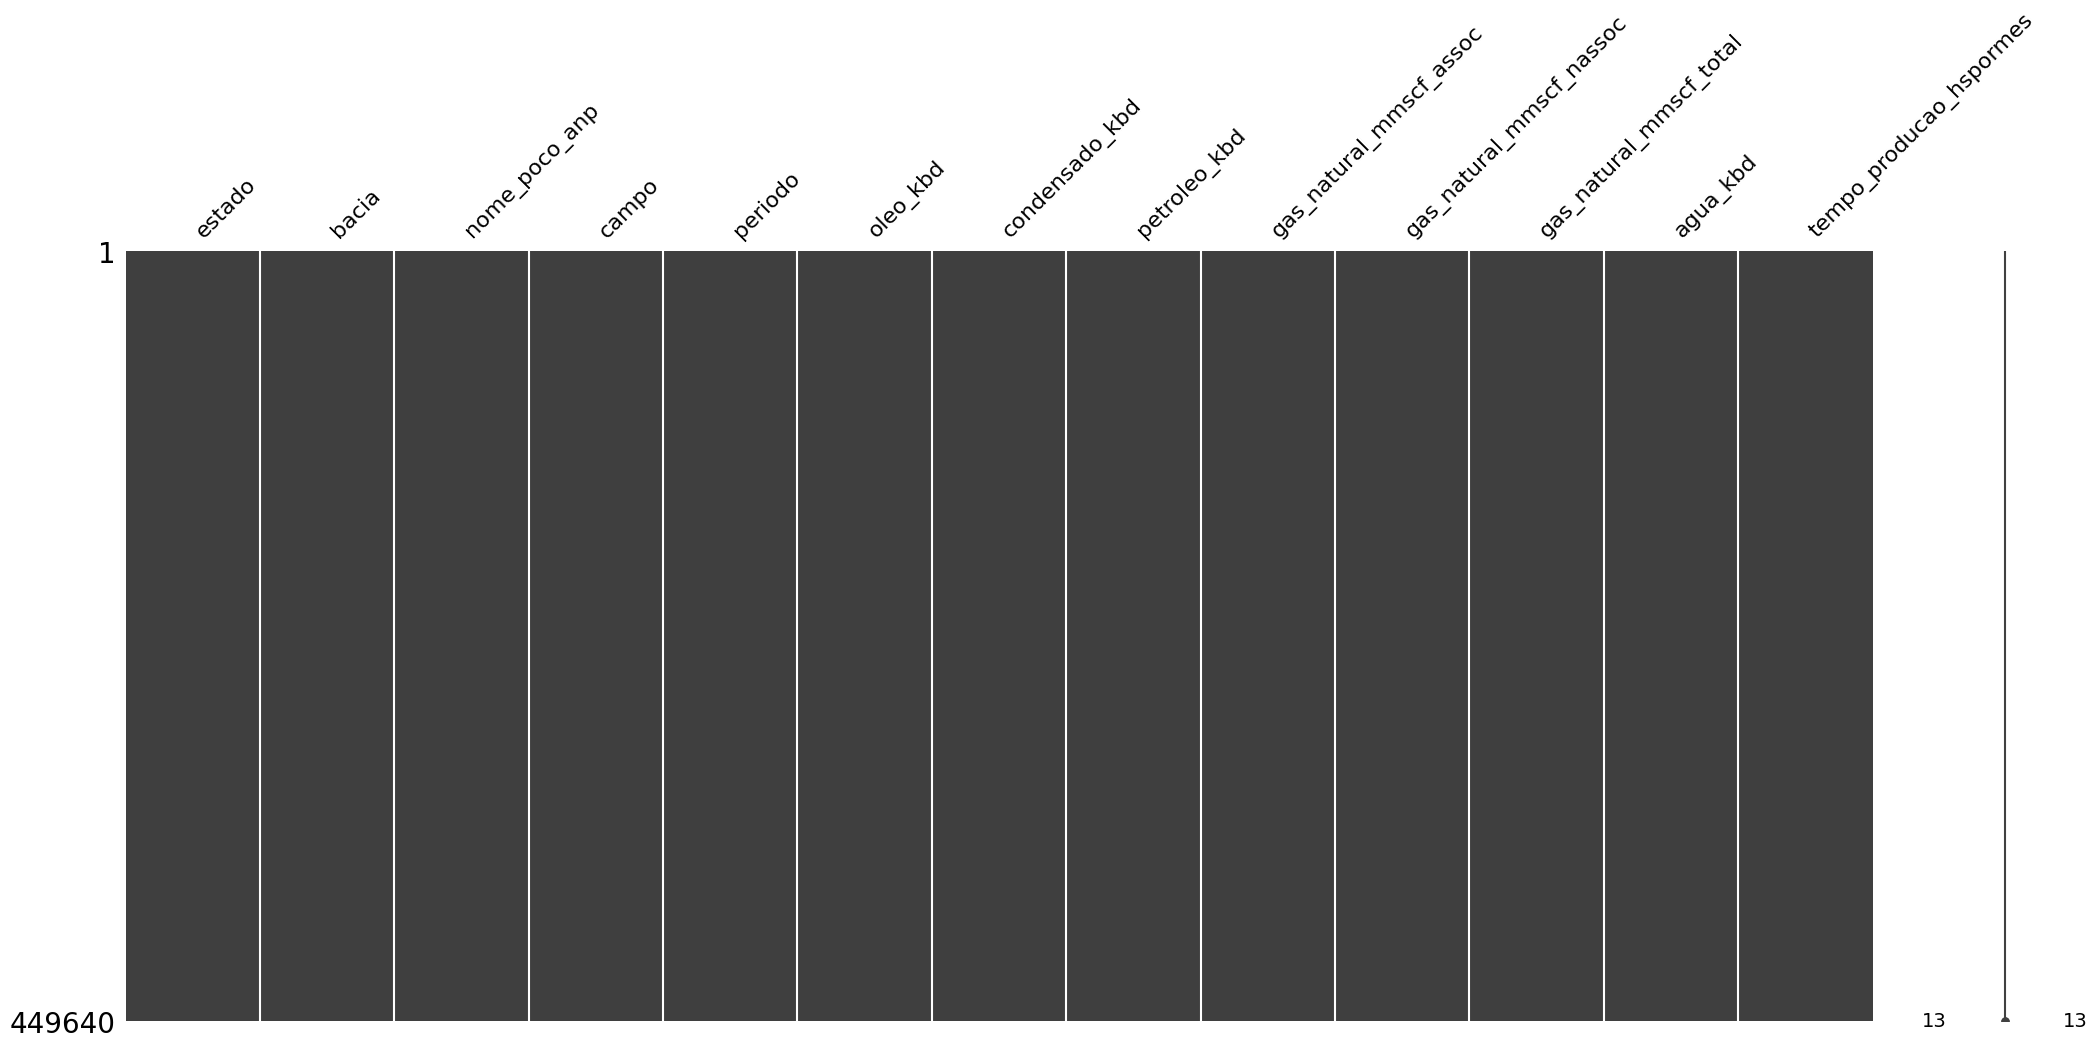

In [101]:
# Visualizar valores nulos
msno.matrix(df_production_clean)

### Verificação quantitativa

Após a estruturação de uma base de dados sólida, iniciamos a fase de visualizações para extrair insights sobre a dinâmica produtiva. O foco inicial é a produção total de petróleo no Pré-Sal, comparando a evolução histórica com o desempenho recente a partir de 2020.

A produção no Pré-Sal brasileiro apresenta um crescimento consistente, demonstrando resiliência mesmo diante dos desafios globais de 2020. Naquele ano, a vazão média registrada foi de aproximadamente 1.036 KBD, resultando em um volume mensal estimado de 31,54 milhões de barris. Este patamar reflete a robustez das operações, que mantiveram a continuidade produtiva apesar das interrupções logísticas e da queda na demanda global causadas pela pandemia.

A recuperação nos anos seguintes foi acentuada. Em 2021 e 2022, a eficiência operacional e a entrada de novos sistemas de produção elevaram os volumes. Em 2023, observamos um salto significativo: a vazão média subiu para 1.212 KBD, elevando o volume mensal para a casa dos 36,89 milhões de barris, um crescimento de cerca de 17% em comparação ao início da década. Esse aumento é impulsionado por técnicas de perfuração mais eficientes e pela maturação de campos estratégicos como Búzios e Tupi.

Para 2024, a projeção indica a manutenção dessa força produtiva. Com base nos dados do primeiro semestre, a vazão média permanece em patamares elevados (~1.201 KBD). Projeta-se um volume mensal estabilizado em 36,54 milhões de barris, confirmando a consolidação do Pré-Sal como o motor da matriz energética nacional.
Observação sobre a Metodologia de Projeção

Para garantir a comparabilidade entre os anos, os valores apresentados foram convertidos de vazão diária (KBD) para volume mensal.

- Cálculo Base: Multiplicamos a soma da vazão diária pelo fator 30,42 (média de dias por mês), resultando no volume mensal em milhões de barris (MMbbl).

- Projeção 2024: Como dispomos apenas dos dados do primeiro semestre, o fator aplicado foi de 60,84. Este número deriva da conversão da vazão diária para volume mensal média (30,42) multiplicada pelo fator de expansão semestral (x2), permitindo uma estimativa anualizada baseada na performance operacional corrente.

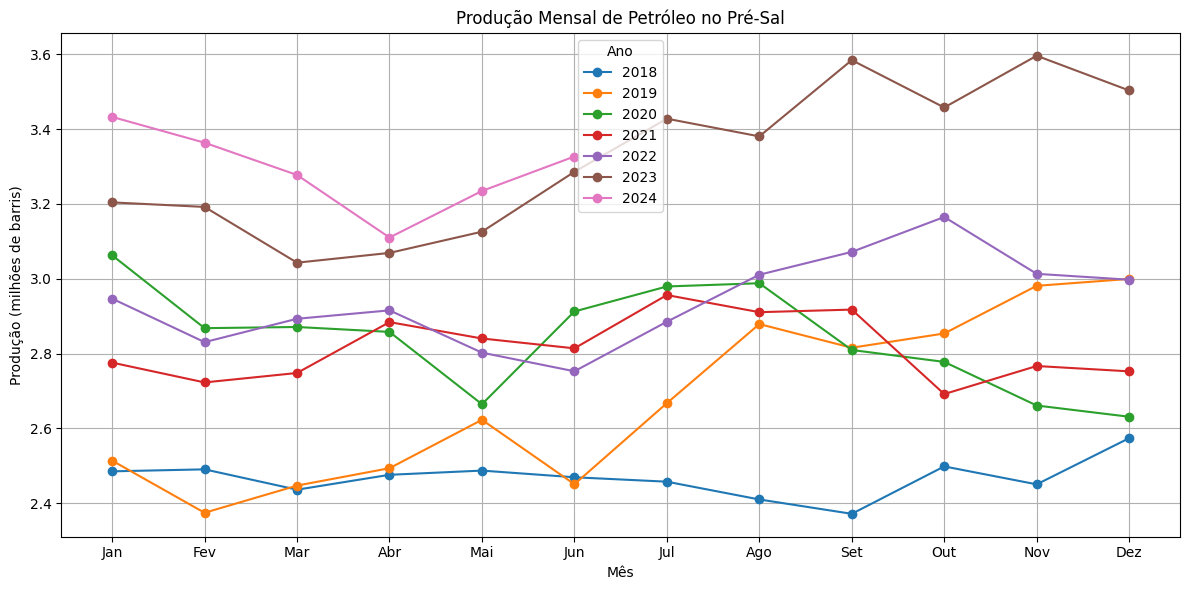

Produção total de petróleo no pré-sal em 1980, em milhões de barris: 27.26
Produção total de petróleo no pré-sal em 1981, em milhões de barris: 36.53
Produção total de petróleo no pré-sal em 1982, em milhões de barris: 51.48
Produção total de petróleo no pré-sal em 1983, em milhões de barris: 71.74
Produção total de petróleo no pré-sal em 1984, em milhões de barris: 113.95
Produção total de petróleo no pré-sal em 1985, em milhões de barris: 142.86
Produção total de petróleo no pré-sal em 1986, em milhões de barris: 148.16
Produção total de petróleo no pré-sal em 1987, em milhões de barris: 144.84
Produção total de petróleo no pré-sal em 1988, em milhões de barris: 136.89
Produção total de petróleo no pré-sal em 1989, em milhões de barris: 146.27
Produção total de petróleo no pré-sal em 1990, em milhões de barris: 161.59
Produção total de petróleo no pré-sal em 1991, em milhões de barris: 162.30
Produção total de petróleo no pré-sal em 1992, em milhões de barris: 161.11
Produção total d

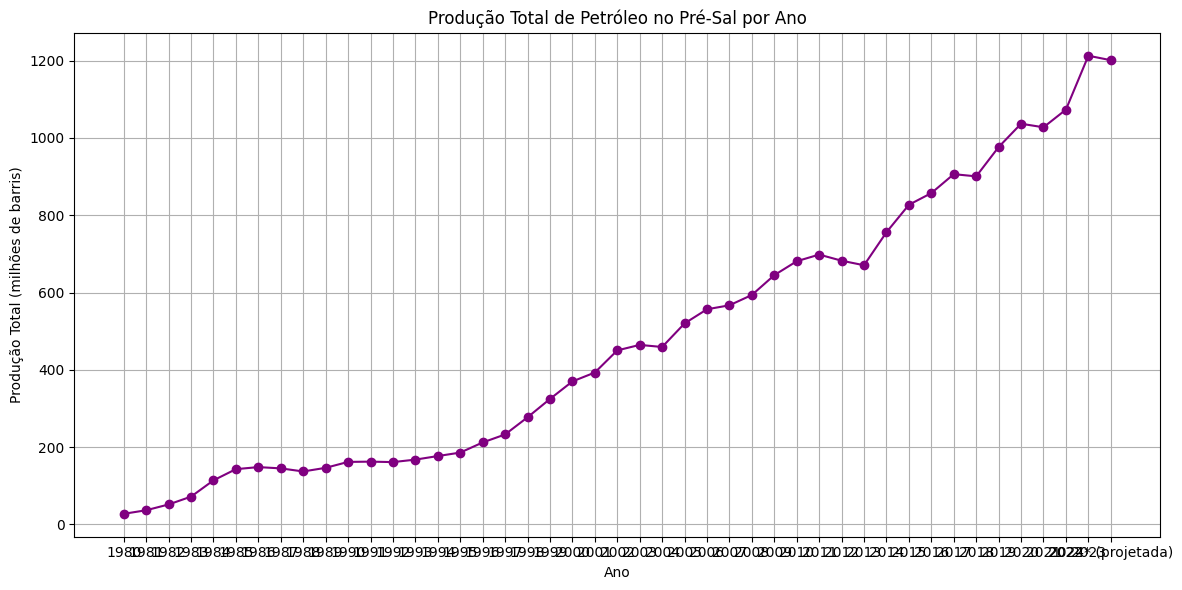

In [102]:
# Adicionar colunas de ano e mês ao DataFrame
df_production_clean['ano'] = df_production_clean['periodo'].dt.year
df_production_clean['mes'] = df_production_clean['periodo'].dt.month

# Filtrar dados de 2018 a 2024 para o gráfico de produção mensal
df_production_filtered = df_production_clean[(df_production_clean['ano'] >= 2018) & (df_production_clean['ano'] <= 2024)]

# Agrupar os dados por ano e mês e somar a produção
producoes_mensais = df_production_filtered.groupby(['ano', 'mes'])['oleo_kbd'].sum().unstack()

# Criando gráfico de linhas para produção mensal
plt.figure(figsize=(12, 6))
for ano in producoes_mensais.index:
    plt.plot(producoes_mensais.columns, producoes_mensais.loc[ano] / 1000, marker='o', label=ano)  # Convertendo para milhões de barris

plt.title('Produção Mensal de Petróleo no Pré-Sal')
plt.xlabel('Mês')
plt.ylabel('Produção (milhões de barris)')
plt.xticks(range(1, 13), ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
plt.legend(title='Ano')
plt.grid()
plt.tight_layout()
plt.show()

# Agrupar os dados por ano e somar a produção
producoes_anuais = df_production_clean.groupby('ano')['oleo_kbd'].sum() / 1000  # Convertendo para milhões de barris

# Projetar a produção total de 2024
for year in producoes_anuais.index:
  if year == 2024:
    producoes_anuais[year] *= 60.84  # Multiplicando por 60.84 para projetar a produção de 2024
  else:
      producoes_anuais[year] *= 30.42

# Exibir o resultado para cada ano
for ano, media in producoes_anuais.items():
    print(f"Produção total de petróleo no pré-sal em {ano}, em milhões de barris: {media:.2f}")

# Criando gráfico de linhas para produção total anual
plt.figure(figsize=(12, 6))

# Criar uma lista de strings para os anos, incluindo a projeção para 2024
anos_strings = [str(year) for year in range(1980, 2024)]
anos_strings.append('2024* (projetada)')
print(anos_strings)

# Usar a lista de strings para os rótulos do eixo x
plt.plot(anos_strings, producoes_anuais.values, marker='o', color='purple', linestyle='-')
plt.title('Produção Total de Petróleo no Pré-Sal por Ano')
plt.xlabel('Ano')
plt.ylabel('Produção Total (milhões de barris)')
plt.grid()
plt.tight_layout()
plt.show()


In [103]:
display(producoes_anuais)
display(producoes_mensais)

,oleo_kbd
ano,
1980,27.261119
1981,36.526313
1982,51.484092
1983,71.737487
1984,113.946842
1985,142.856038
1986,148.161527
1987,144.840708
1988,136.887005


mes,1,2,3,4,5,6,7,8,9,10,11,12
ano,,,,,,,,,,,,
2018,2485.152812,2490.495515,2436.115123,2475.918145,2487.148357,2469.314287,2457.504819,2409.984222,2371.632743,2498.331324,2450.403301,2573.788107
2019,2513.773209,2374.443017,2447.100967,2493.554322,2622.857896,2450.686291,2667.354865,2878.693265,2815.463550,2853.598910,2980.914331,2999.413408
2020,3062.517368,2867.775893,2870.923755,2857.785167,2664.527943,2912.385503,2979.200812,2987.848798,2809.476886,2777.611934,2661.081653,2631.041519
2021,2775.723352,2722.759554,2748.010733,2883.971682,2840.205074,2813.856212,2956.269095,2910.493084,2917.406179,2691.647801,2766.651552,2752.370056
2022,2946.702584,2830.428877,2892.904196,2915.342462,2802.342368,2752.550422,2884.973014,3010.568453,3071.601106,3164.872364,3013.008067,2997.301565
2023,3203.919701,3191.772838,3042.790942,3068.874993,3125.561374,3285.629678,3427.590919,3380.327392,3584.081824,3457.507268,3595.826918,3503.029058
2024,3432.317791,3363.397831,3277.132719,3110.009194,3234.427176,3326.527323,NaN,NaN,NaN,NaN,NaN,NaN


#### Observação

A produção de petróleo no ano de 2024, até o momento, é de 15,68 milhões de barris, correspondente aos dados disponíveis apenas até o meio do ano. Isso significa que, para ter uma estimativa da produção total anual, precisamos projetar a produção do restante do ano com base nos dados atuais.

Como estamos analisando apenas os primeiros seis meses de 2024, multiplicamos a produção registrada até agora por 2. Esta projeção assume que a produção dos próximos seis meses será semelhante à produção dos primeiros seis meses. Essa abordagem é comum em análises de produção quando os dados disponíveis são limitados, permitindo estimar um total anual mais realista, porém bem conservadora.

Projeção para o ano: 15,68 milhões de barris × 2 = 31,36 milhões de barris projetados para 2024.

### Análises de correlações

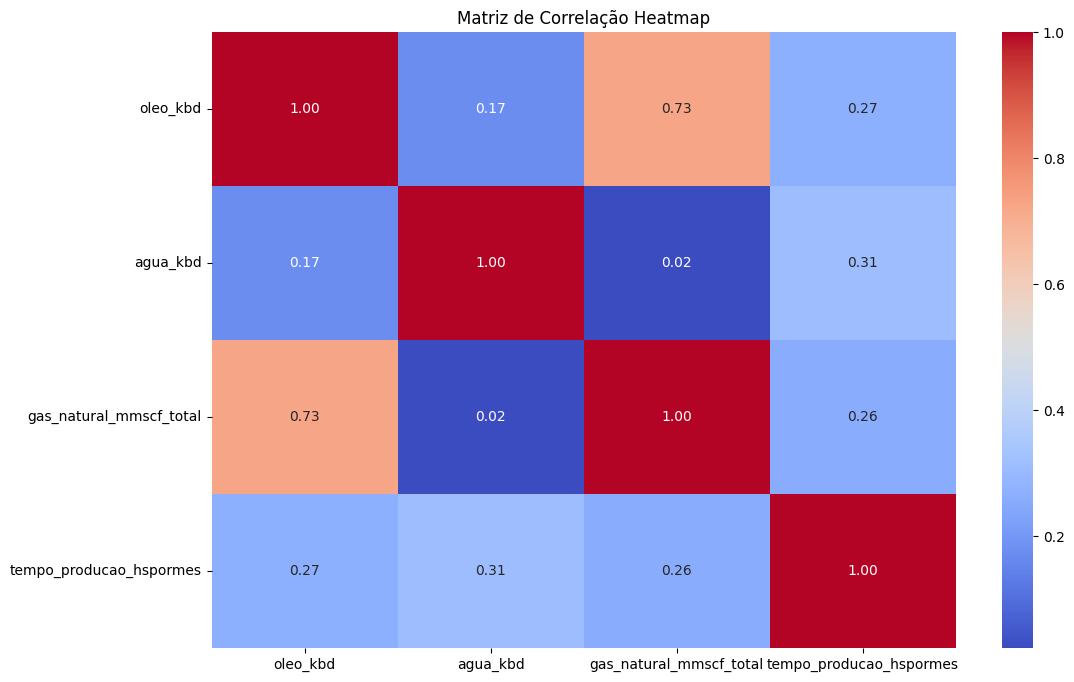

In [104]:
# Filtrar apenas algumas colunas numéricas para analises de correlação (float64, int64)
colunas_numericas = ['oleo_kbd', 'agua_kbd', 'gas_natural_mmscf_total', 'tempo_producao_hspormes']

# Matriz de correlação apenas para colunas numéricas
correlacoes = df_production_clean[colunas_numericas].corr()

# Visualizar a matriz de correlação com um heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlacoes, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlação Heatmap')
plt.show()

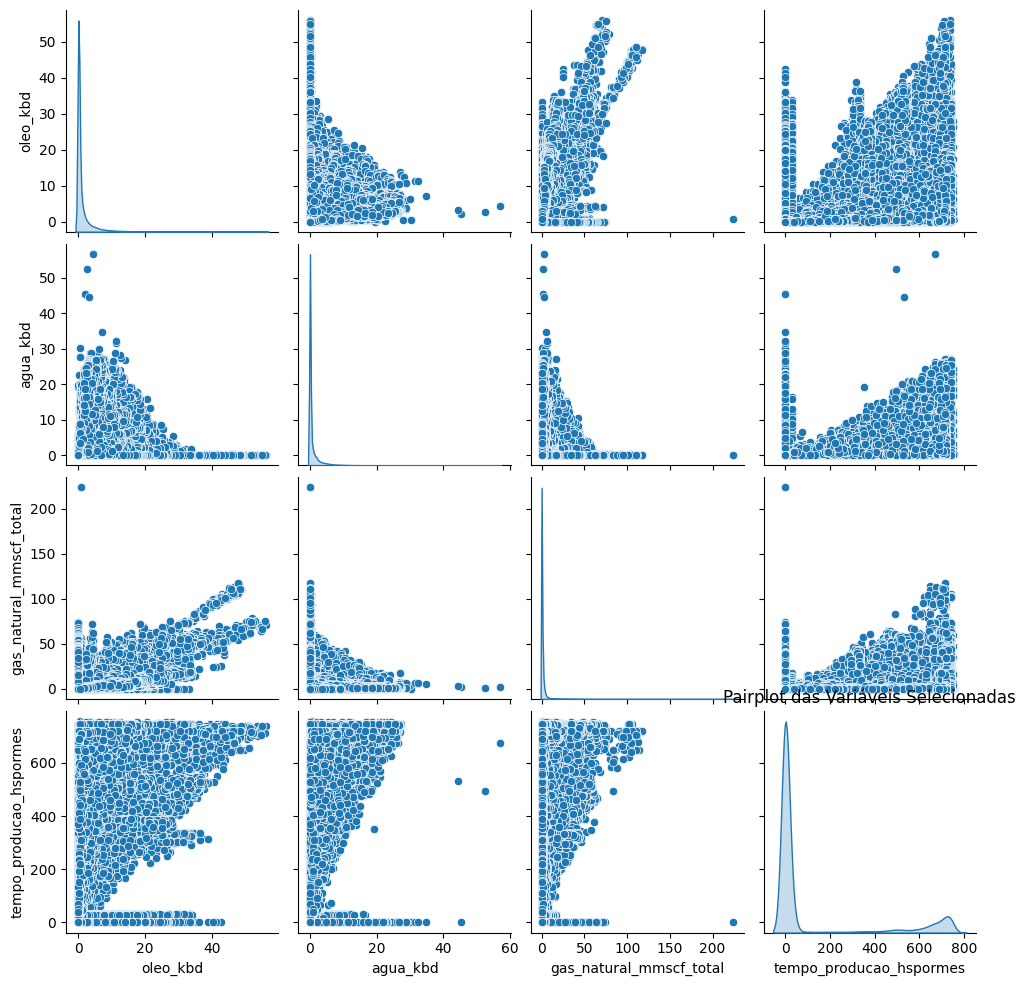

In [105]:
# Criar o pairplot com o subconjunto de colunas
sns.pairplot(df_production_clean[colunas_numericas], diag_kind='kde')
plt.title('Pairplot das Variáveis Selecionadas')
plt.show()

### Boxplots para detectar a distribuição e possíveis outliers

A maior parte da produção de óleo e gás está concentrada em poços de baixa a moderada produtividade. No entanto, há alguns poços com produções significativamente altas (outliers), o que pode indicar que a produção não está distribuída de forma uniforme entre os poços.

Já o tempo de produção por poço apresenta uma boa consistência da produção Brasileira no Pré-Sal nos últimos 5 anos. A maioria dos poços de petróleo parece operar por aproximadamente 20 a 29 dias por mês, o que representa entre 70% e 97% do mês. Poucos meses atingem a capacidade máxima de 720 horas (30 dias completos), indicando que paradas de produção são comuns. A presença de outliers sugere que, em alguns meses, os poços operaram por bem menos de 12 dias, o que pode ter sido causado por problemas ou manutenções específicas.



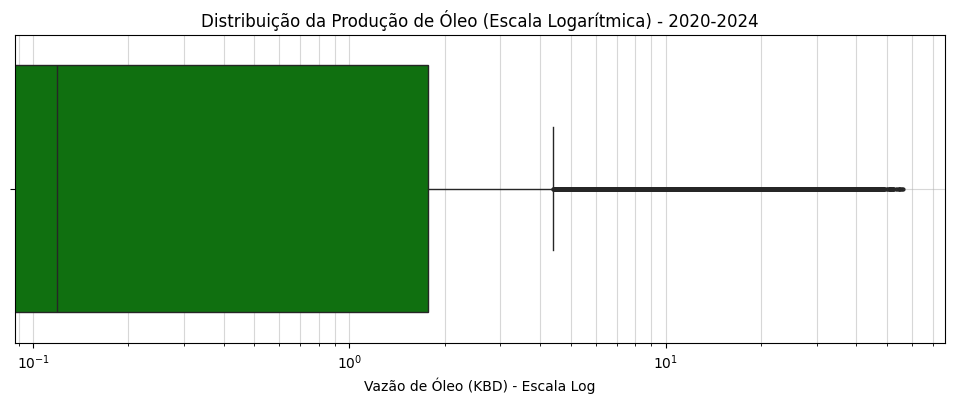

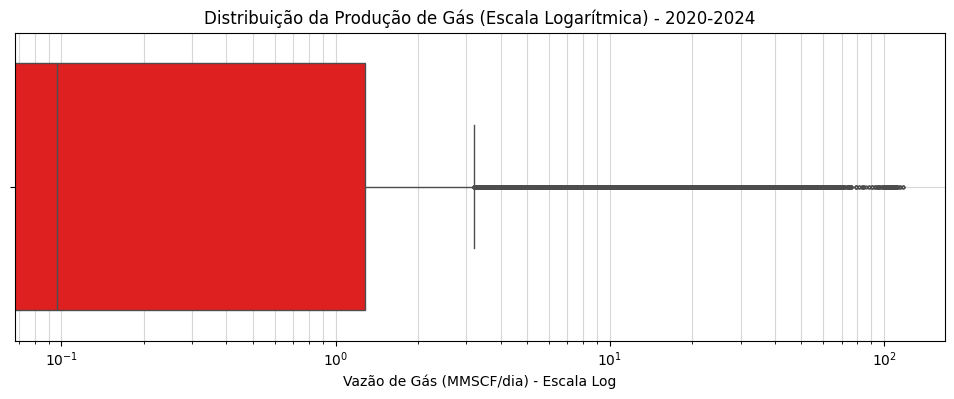

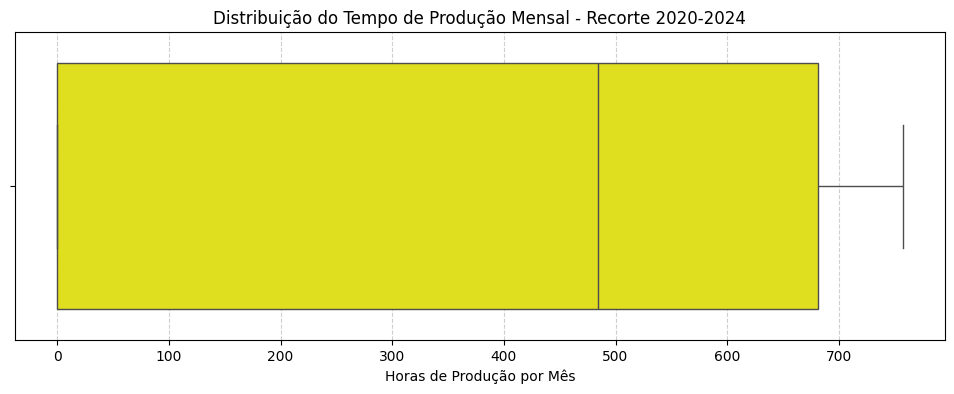

In [123]:
# Criando um recorte de dados apenas de 2020 em diante para visualização legível
df_recente = df_production_clean[df_production_clean['ano'] >= 2020]

# 1. Boxplot para a produção de óleo (Escala Logarítmica)
plt.figure(figsize=(12, 4))
sns.boxplot(data=df_recente, x='oleo_kbd', color='green', fliersize=2)
plt.xscale('log')
plt.title('Distribuição da Produção de Óleo (Escala Logarítmica) - 2020-2024')
plt.xlabel('Vazão de Óleo (KBD) - Escala Log')
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

# 2. Boxplot para a produção de gás (Escala Logarítmica)
plt.figure(figsize=(12, 4))
sns.boxplot(data=df_recente, x='gas_natural_mmscf_total', color='red', fliersize=2)
plt.xscale('log')
plt.title('Distribuição da Produção de Gás (Escala Logarítmica) - 2020-2024')
plt.xlabel('Vazão de Gás (MMSCF/dia) - Escala Log')
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

# 3. Boxplot para tempo de produção (Escala Linear)
plt.figure(figsize=(12, 4))
sns.boxplot(data=df_recente, x='tempo_producao_hspormes', color='yellow')
plt.title('Distribuição do Tempo de Produção Mensal - Recorte 2020-2024')
plt.xlabel('Horas de Produção por Mês')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

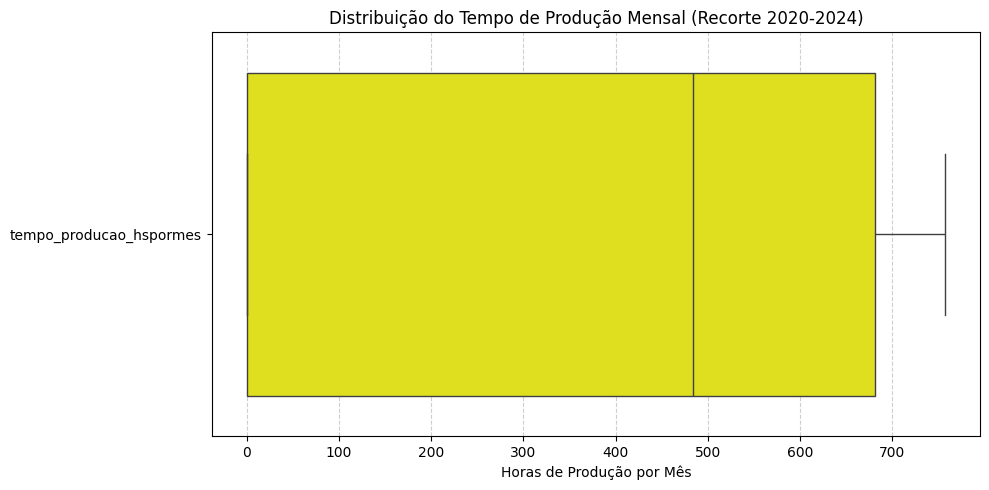

In [121]:
# Boxplot para detectar a distribuição de horas de produção (Recorte 2020+)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_recente[['tempo_producao_hspormes']], color='yellow', orient='h')

plt.title('Distribuição do Tempo de Produção Mensal (Recorte 2020-2024)')
plt.xlabel('Horas de Produção por Mês')
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Visualização temporal da produção

Ao longo dos últimos cinco anos, a análise da produção de óleo e gás no pré-sal revela uma evolução significativa em ambas as frentes. Utilizando visualizações temporais, foi possível acompanhar a variação mês a mês, proporcionando insights sobre a tendência de produção no período avaliado.

Contudo, ao analisar os dados mais recentes, nota-se uma desaceleração que indica uma estagnação nos últimos meses. Os gráficos apontam para uma estabilização ou até uma leve queda tanto na produção de óleo quanto de gás. Isso pode estar relacionado a uma série de fatores como mudança na demanda global por petróleo, a transição para energias mais limpas, a alta dos preços, as preocupações com a segurança no fornecimento de energia, desaceleração da China entre outros fatores.

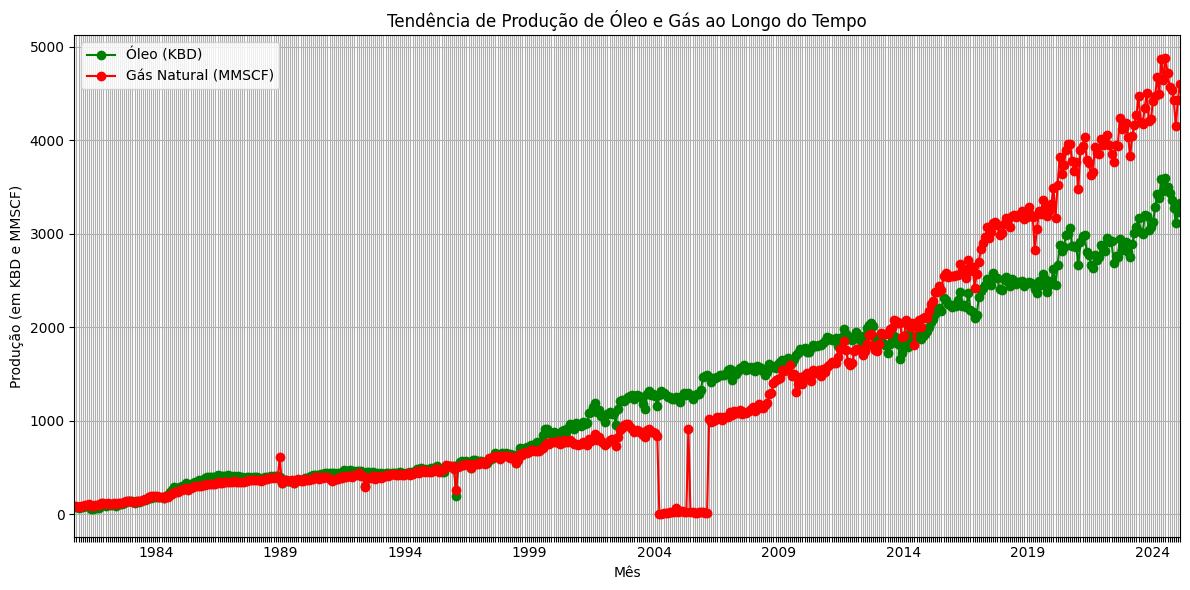

In [108]:
# Ajustando o gráfico para exibir todos os meses do ano no eixo X
plt.figure(figsize=(12, 6))

# Agrupando por período (mês) e somando as produções de óleo e gás
df_production_clean.groupby('periodo')['oleo_kbd'].sum().plot(label='Óleo (KBD)', marker='o', color='green')
df_production_clean.groupby('periodo')['gas_natural_mmscf_total'].sum().plot(label='Gás Natural (MMSCF)', marker='o', color='red')

# Título e legenda
plt.title('Tendência de Produção de Óleo e Gás ao Longo do Tempo')
plt.xlabel('Mês')
plt.ylabel('Produção (em KBD e MMSCF)')
plt.legend()

# Melhorando visualização do eixo X para mostrar mês e ano
plt.xticks(df_production_clean['periodo'].dt.to_period('M').unique(), rotation=0, ha='right')  # Exibe no formato "Jan 2020", "Fev 2020", etc.
plt.grid(True)  # Adiciona grades para melhor visualização das inclinações

# Ajuste o layout para evitar sobreposição
plt.tight_layout()

# Exibe o gráfico
plt.show()

### Visualização dos Maiores Campos Produtores do Pré-Sal

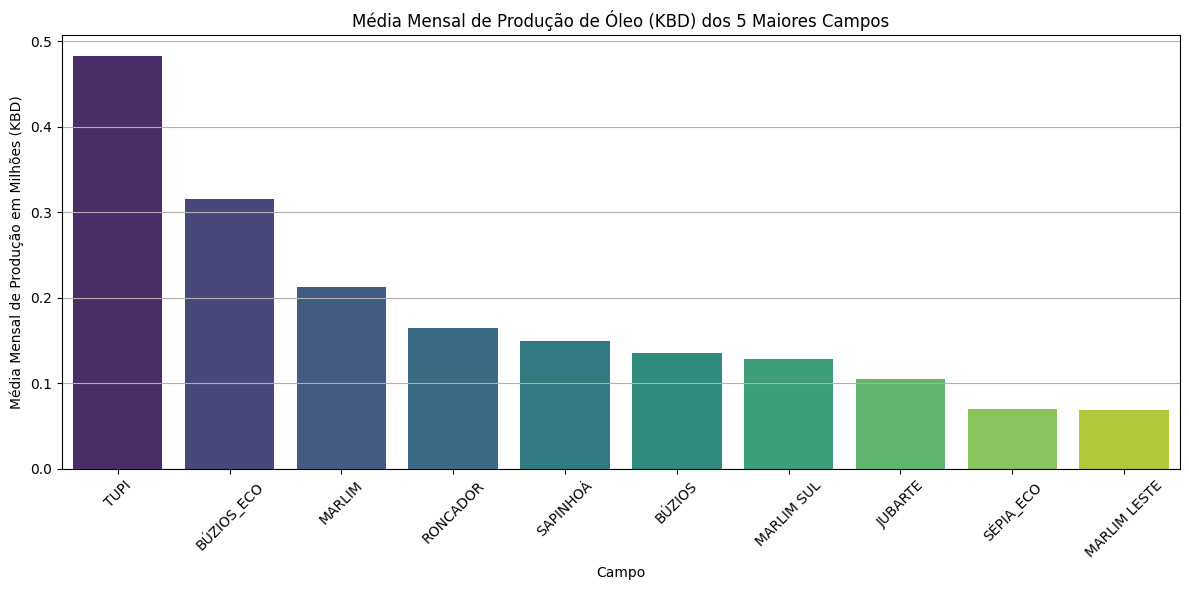

In [109]:
# Adicionar coluna de ano ao DataFrame
df_production_clean['ano'] = df_production_clean['periodo'].dt.year

# Agrupar a produção total por ano e converter para KBD
producoes_totais_anuais = df_production_clean.groupby('ano')['oleo_kbd'].sum() / 1000  # Convertendo para KBD

# Filtrar para campos que produziram
df_producao_produtiva = df_production_clean[df_production_clean['oleo_kbd'] > 0]

# Agrupar a produção por campo e ano, somando a produção
producoes_campos_anuais = (df_producao_produtiva.groupby(['ano', 'campo'])['oleo_kbd'].sum() / 1000).reset_index()  # Convertendo para KBD

# Calcular a média mensal
producoes_campos_anuais['Media_Mensal_KBD'] = producoes_campos_anuais['oleo_kbd'] / 12

# Selecionar os 5 maiores campos por média mensal
top_5 = producoes_campos_anuais.groupby('campo')['Media_Mensal_KBD'].mean().nlargest(10).reset_index()

# Criar gráfico de barras para a média mensal dos 5 maiores campos
plt.figure(figsize=(12, 6))
sns.barplot(x='campo', y='Media_Mensal_KBD', data=top_5, palette='viridis')
plt.xticks(rotation=45)
plt.title('Média Mensal de Produção de Óleo (KBD) dos 5 Maiores Campos')
plt.xlabel('Campo')
plt.ylabel('Média Mensal de Produção em Milhões (KBD)')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

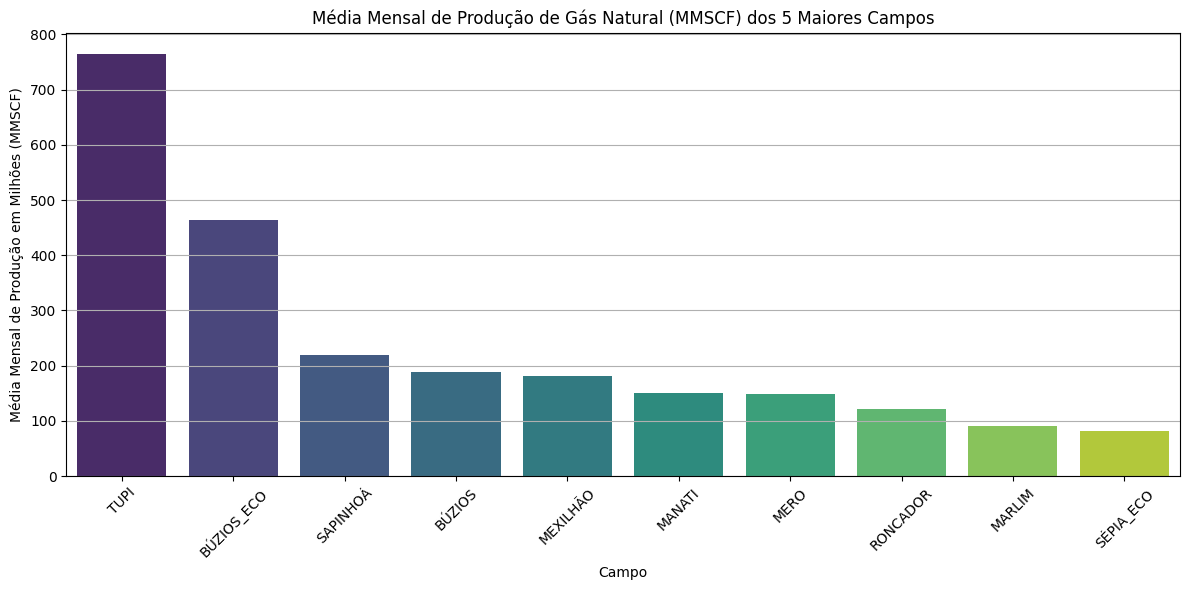

In [110]:
# Agrupar a produção total de gás natural por ano e converter para MMSCF
producoes_totais_anuais_gas = df_production_clean.groupby('ano')['gas_natural_mmscf_total'].sum()  # Total por ano

# Filtrar para campos que produziram gás
df_producao_produtiva_gas = df_production_clean[df_production_clean['gas_natural_mmscf_total'] > 0]

# Agrupar a produção por campo e ano, somando a produção de gás
producoes_campos_anuais_gas = (df_producao_produtiva_gas.groupby(['ano', 'campo'])['gas_natural_mmscf_total'].sum()).reset_index()

# Calcular a média mensal
producoes_campos_anuais_gas['Media_Mensal_MMSCF'] = producoes_campos_anuais_gas['gas_natural_mmscf_total'] / 12

# Selecionar os 5 maiores campos por média mensal
top_5_gas = producoes_campos_anuais_gas.groupby('campo')['Media_Mensal_MMSCF'].mean().nlargest(10).reset_index()

# Criar gráfico de barras para a média mensal dos 5 maiores campos
plt.figure(figsize=(12, 6))
sns.barplot(x='campo', y='Media_Mensal_MMSCF', data=top_5_gas, palette='viridis')
plt.xticks(rotation=45)
plt.title('Média Mensal de Produção de Gás Natural (MMSCF) dos 5 Maiores Campos')
plt.xlabel('Campo')
plt.ylabel('Média Mensal de Produção em Milhões (MMSCF)')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


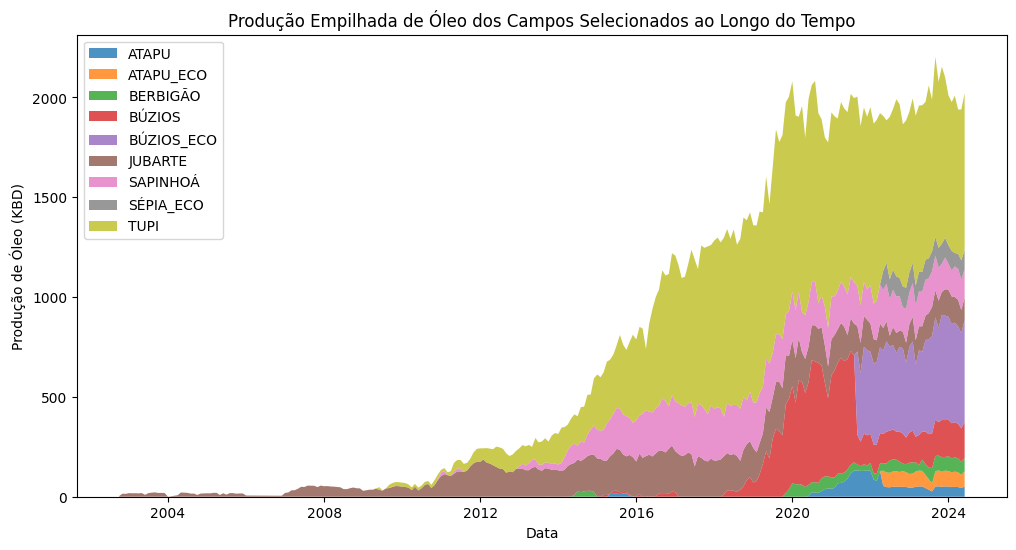

In [111]:
# Filtrar para os campos desejados
campos_selecionados = [
    'TUPI', 'BÚZIOS_ECO', 'BÚZIOS', 'SAPINHOÁ', 'MERGULHO',
    'JUBARTE', 'SÉPIA_ECO', 'ATAPU_ECO', 'ATAPU', 'BERBIGÃO'
]

df_campos_selecionados = df_production_clean[df_production_clean['campo'].isin(campos_selecionados)]

# Agrupando por período (mês) e campo, somando as produções de óleo
producoes_mensais = df_campos_selecionados.groupby(['periodo', 'campo'])['oleo_kbd'].sum().reset_index()

# Criar uma coluna de Data para o eixo X
producoes_mensais['data'] = pd.to_datetime(producoes_mensais['periodo'])

# Pivotar os dados para um formato adequado para o gráfico empilhado
producoes_pivotadas = producoes_mensais.pivot(index='data', columns='campo', values='oleo_kbd').fillna(0)

# Criar gráfico empilhado
plt.figure(figsize=(12, 6))
plt.stackplot(
    producoes_pivotadas.index,
    producoes_pivotadas.T,  # Transpor para que os campos sejam as séries
    labels=producoes_pivotadas.columns,
    alpha=0.8
)

# Título e legendas
plt.title('Produção Empilhada de Óleo dos Campos Selecionados ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Produção de Óleo (KBD)')
plt.legend(loc='upper left')

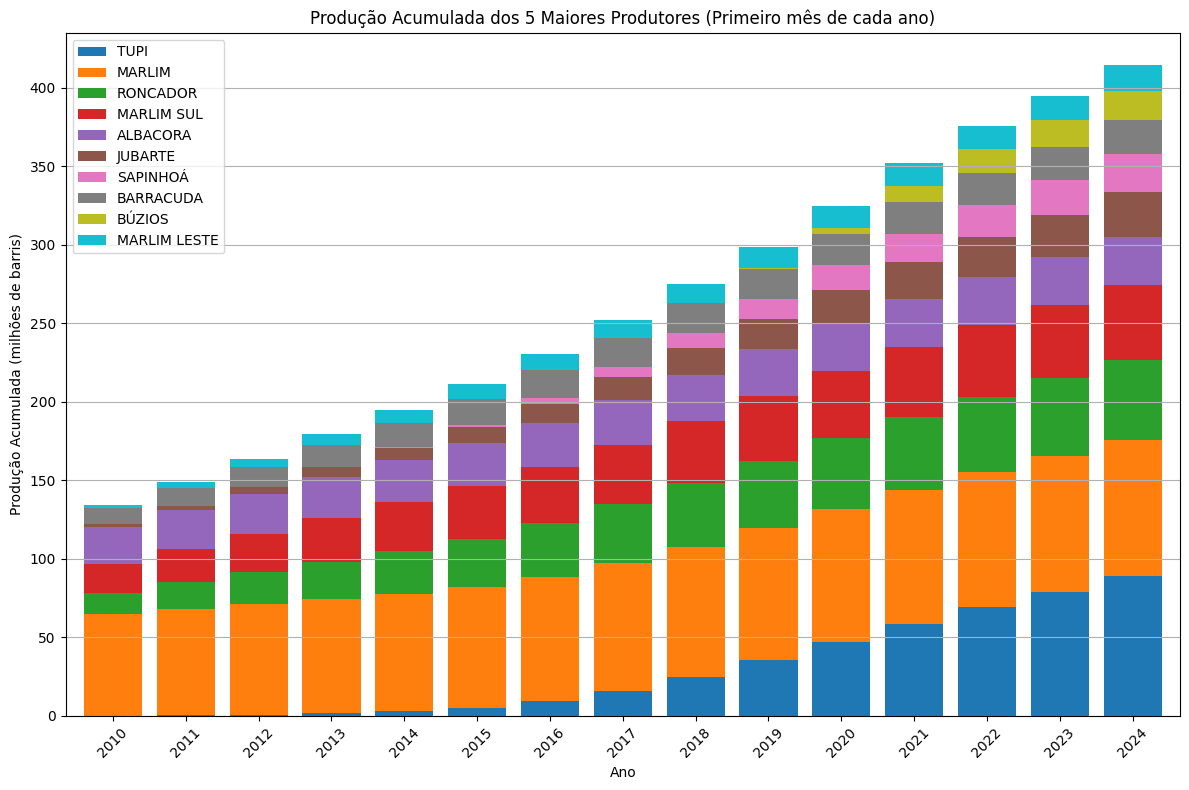

In [112]:
# Encontrar os 5 maiores produtores
maiores_produtores = df_production_clean.groupby('campo')['oleo_kbd'].sum().nlargest(10).index.tolist()

# Criar um DataFrame para a produção acumulada
df_acumulado = pd.DataFrame()

for campo in maiores_produtores:
    # Filtrar dados para o campo atual
    df_campo = df_production_clean[df_production_clean['campo'] == campo]

    # Agrupar por período e somar a produção
    producoes_diarias = df_campo.groupby(df_campo['periodo'].dt.date)['oleo_kbd'].sum()

    # Calcular a produção acumulada
    producoes_acumuladas = producoes_diarias.cumsum() / 1000  # Convertendo para milhões de barris

    # Adicionar ao DataFrame
    df_acumulado[campo] = producoes_acumuladas

# Convertendo o índice para datetime, caso não esteja no formato correto
df_acumulado.index = pd.to_datetime(df_acumulado.index)

# Agora, filtrar apenas o primeiro mês de cada ano
df_acumulado_ano = df_acumulado[df_acumulado.index.month == 1]

# Filtrar para remover 2015 e 2016
df_acumulado_ano = df_acumulado_ano[df_acumulado_ano.index.year >= 1990]

# Criar gráfico de barras empilhadas
plt.figure(figsize=(12, 8))
df_acumulado_ano.plot(kind='bar', stacked=True, colormap='tab10', ax=plt.gca(), width=0.8)

# Configurações do gráfico
plt.title('Produção Acumulada dos 5 Maiores Produtores (Primeiro mês de cada ano)')
plt.xlabel('Ano')
plt.ylabel('Produção Acumulada (milhões de barris)')

# Ajustar o eixo X para mostrar apenas os anos
plt.xticks(ticks=range(len(df_acumulado_ano)), labels=df_acumulado_ano.index.year, rotation=45)

# Adicionar grade ao gráfico
plt.grid(axis='y')

# Ajustar layout para não cortar a legenda
plt.tight_layout()

# Exibir o gráfico
plt.show()

# Exibir o DataFrame e verificar os tipos de dados
#display(df_acumulado_ano)
#print(df_acumulado_ano.dtypes)

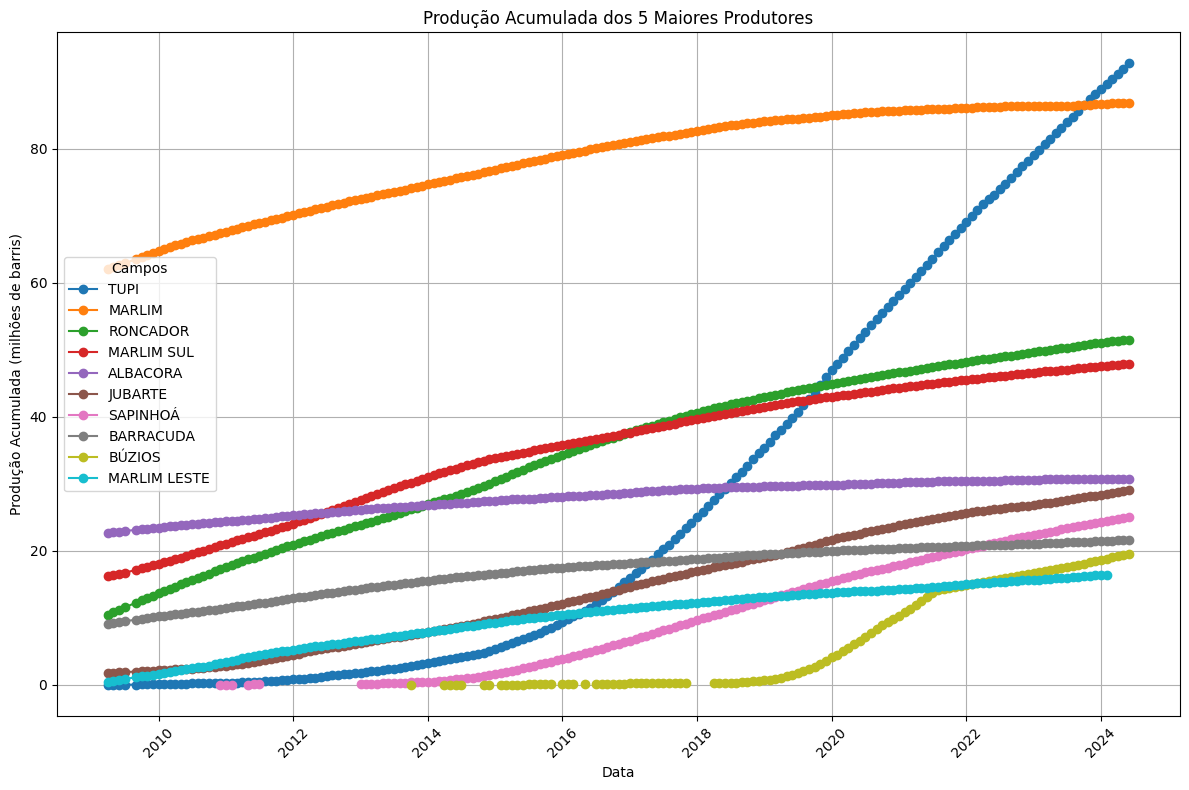

In [113]:
# Encontrar os 5 maiores produtores
maiores_produtores = df_production_clean.groupby('campo')['oleo_kbd'].sum().nlargest(10).index.tolist()

# Criar um DataFrame para a produção acumulada
df_acumulado = pd.DataFrame()

for campo in maiores_produtores:
    # Filtrar dados para o campo atual
    df_campo = df_production_clean[df_production_clean['campo'] == campo]

    # Agrupar por período e somar a produção
    producoes_diarias = df_campo.groupby(df_campo['periodo'].dt.date)['oleo_kbd'].sum()

    # Calcular a produção acumulada
    producoes_acumuladas = producoes_diarias.cumsum() / 1000  # Convertendo para milhões de barris

    # Adicionar ao DataFrame
    df_acumulado[campo] = producoes_acumuladas

# Criar gráfico de linhas
plt.figure(figsize=(12, 8))

# Plotar cada campo em uma linha
for campo in df_acumulado.columns:
    plt.plot(df_acumulado.index, df_acumulado[campo], marker='o', label=campo)

# Configurações do gráfico
plt.title('Produção Acumulada dos 5 Maiores Produtores')
plt.xlabel('Data')
plt.ylabel('Produção Acumulada (milhões de barris)')
plt.xticks(rotation=45)
plt.grid()
plt.legend(title='Campos')
plt.tight_layout()

# Exibir o gráfico
plt.show()

In [114]:
# Step 1: Import required module
from google.colab import files

# Step 2: Save your DataFrame to a CSV file
df_production_clean.to_csv('1980_2024_mar-presal_oil-gas-water_prod_rev2.csv')

# Step 3: Download the file to your local machine
files.download('1980_2024_mar-presal_oil-gas-water_prod_rev2.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [115]:
df_production_clean.to_parquet('1980_2024_BR_production_data.parquet')
# Step 3: Download the file to your local machine
files.download('1980_2024_BR_production_data.parquet')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Normalização e Padronização dos Dados

Normalização e padronização são técnicas essenciais na pré-processamento de dados, especialmente em contextos de machine learning e análise de dados. Ambas têm como objetivo transformar os dados de entrada, mas fazem isso de maneiras diferentes.

O trecho de código que utiliza MinMaxScaler() aplica a normalização, escalando os dados para um intervalo entre 0 e 1. O trecho que utiliza StandardScaler() aplica a padronização, transformando os dados para que tenham média zero e desvio padrão um, que possivelmente será a técnica utilizada quando formos trabalhar com os modelos de Machine Learning devido à natureza do dado se assemelhar à curvas normais. Porém será necessário validar e avaliar caso a caso para garantir o melhor orientando-se aos dados.

In [116]:
# Verificar valores faltantes
missing_values = df_production.isnull().sum()
print(missing_values[missing_values > 0])

# Exemplo de remoção de linhas com valores faltantes
df_production.dropna(inplace=True)

Series([], dtype: int64)


In [117]:
# Separar colunas numéricas
colunas_numericas = [
    "oleo_kbd", "petroleo_kbd", "gas_natural_mmscf_assoc",
    "gas_natural_mmscf_nassoc", "gas_natural_mmscf_total",
    "agua_kbd", "tempo_producao_hspormes"
    ]

# Criar cópias do DataFrame original para normalização e padronização
df_production_normal = df_production.copy()
df_production_padrao = df_production.copy()

# Normalização
scaler_minmax = MinMaxScaler()
df_production_normal[colunas_numericas] = scaler_minmax.fit_transform(df_production[colunas_numericas])

# Padronização
scaler_standard = StandardScaler()
df_production_padrao[colunas_numericas] = scaler_standard.fit_transform(df_production[colunas_numericas])

# Exibir as primeiras linhas dos novos DataFrames
display('Producão Normalizada', df_production_normal.head(10))
display('Produção Padronizada', df_production_padrao.head(10))


'Producão Normalizada'

,estado,bacia,nome_poco_anp,campo,periodo,oleo_kbd,condensado_kbd,petroleo_kbd,gas_natural_mmscf_assoc,gas_natural_mmscf_nassoc,gas_natural_mmscf_total,agua_kbd,tempo_producao_hspormes
0,Rio de Janeiro,Campos,3-RJS-159-RJS,PAMPO,2011-01-01,0.005223,0.0,0.005223,0.001286,0.0,0.001286,2.211878e-03,0.0
1,Rio de Janeiro,Campos,7-PM-17D-RJS,PAMPO,2011-01-01,0.003506,0.0,0.003506,0.000487,0.0,0.000487,2.211563e-04,0.0
2,Rio de Janeiro,Campos,6-BRSA-806-RJS,CARATINGA,2011-01-01,0.238218,0.0,0.238218,0.031801,0.0,0.031801,5.913652e-04,0.0
3,Rio de Janeiro,Campos,4-RJS-265A-RJS,TRILHA,2011-01-01,0.004310,0.0,0.004310,0.000793,0.0,0.000793,8.696107e-05,0.0
4,São Paulo,Santos,1-BRSA-594-SPS,SAPINHOÁ,2011-01-01,0.316543,0.0,0.316543,0.087056,0.0,0.087056,9.863925e-08,0.0
5,Rio de Janeiro,Campos,7-BD-7D-RJS,BADEJO,2011-01-01,0.005203,0.0,0.005203,0.000870,0.0,0.000870,5.197408e-05,0.0
6,Rio de Janeiro,Campos,6-BRSA-806-RJS,BARRACUDA,2011-01-01,0.015205,0.0,0.015205,0.002030,0.0,0.002030,3.783872e-05,0.0
7,Rio de Janeiro,Campos,7-BD-9D-RJS,BADEJO,2011-01-01,0.003718,0.0,0.003718,0.002142,0.0,0.002142,3.716234e-05,0.0
8,Rio de Janeiro,Campos,3-BD-15C-RJS,BADEJO,2011-01-01,0.001729,0.0,0.001729,0.000350,0.0,0.000350,8.650310e-06,0.0
9,Espírito Santo,Campos,6-BRSA-639-ESS,JUBARTE,2011-01-01,0.416492,0.0,0.416492,0.130917,0.0,0.130917,9.863925e-08,0.0


'Produção Padronizada'

,estado,bacia,nome_poco_anp,campo,periodo,oleo_kbd,condensado_kbd,petroleo_kbd,gas_natural_mmscf_assoc,gas_natural_mmscf_nassoc,gas_natural_mmscf_total,agua_kbd,tempo_producao_hspormes
0,Rio de Janeiro,Campos,3-RJS-159-RJS,PAMPO,2011-01-01,-0.342828,0.0,-0.343975,-0.245856,-0.093721,-0.265565,-0.323664,-0.525773
1,Rio de Janeiro,Campos,7-PM-17D-RJS,PAMPO,2011-01-01,-0.363458,0.0,-0.364612,-0.272946,-0.093721,-0.291007,-0.371054,-0.525773
2,Rio de Janeiro,Campos,6-BRSA-806-RJS,CARATINGA,2011-01-01,2.455910,0.0,2.455685,0.788457,-0.093721,0.705802,-0.362241,-0.525773
3,Rio de Janeiro,Campos,4-RJS-265A-RJS,TRILHA,2011-01-01,-0.353797,0.0,-0.354947,-0.262563,-0.093721,-0.281255,-0.374249,-0.525773
4,São Paulo,Santos,1-BRSA-594-SPS,SAPINHOÁ,2011-01-01,3.396755,0.0,3.396841,2.661299,-0.093721,2.464668,-0.376317,-0.525773
5,Rio de Janeiro,Campos,7-BD-7D-RJS,BADEJO,2011-01-01,-0.343071,0.0,-0.344218,-0.259971,-0.093721,-0.278821,-0.375082,-0.525773
6,Rio de Janeiro,Campos,6-BRSA-806-RJS,BARRACUDA,2011-01-01,-0.222924,0.0,-0.224031,-0.220646,-0.093721,-0.241889,-0.375418,-0.525773
7,Rio de Janeiro,Campos,7-BD-9D-RJS,BADEJO,2011-01-01,-0.360907,0.0,-0.362060,-0.216861,-0.093721,-0.238335,-0.375434,-0.525773
8,Rio de Janeiro,Campos,3-BD-15C-RJS,BADEJO,2011-01-01,-0.384800,0.0,-0.385961,-0.277576,-0.093721,-0.295355,-0.376113,-0.525773
9,Espírito Santo,Campos,6-BRSA-639-ESS,JUBARTE,2011-01-01,4.597343,0.0,4.597824,4.147985,-0.093721,3.860878,-0.376317,-0.525773


### Visualização da Normalização e da Padronização

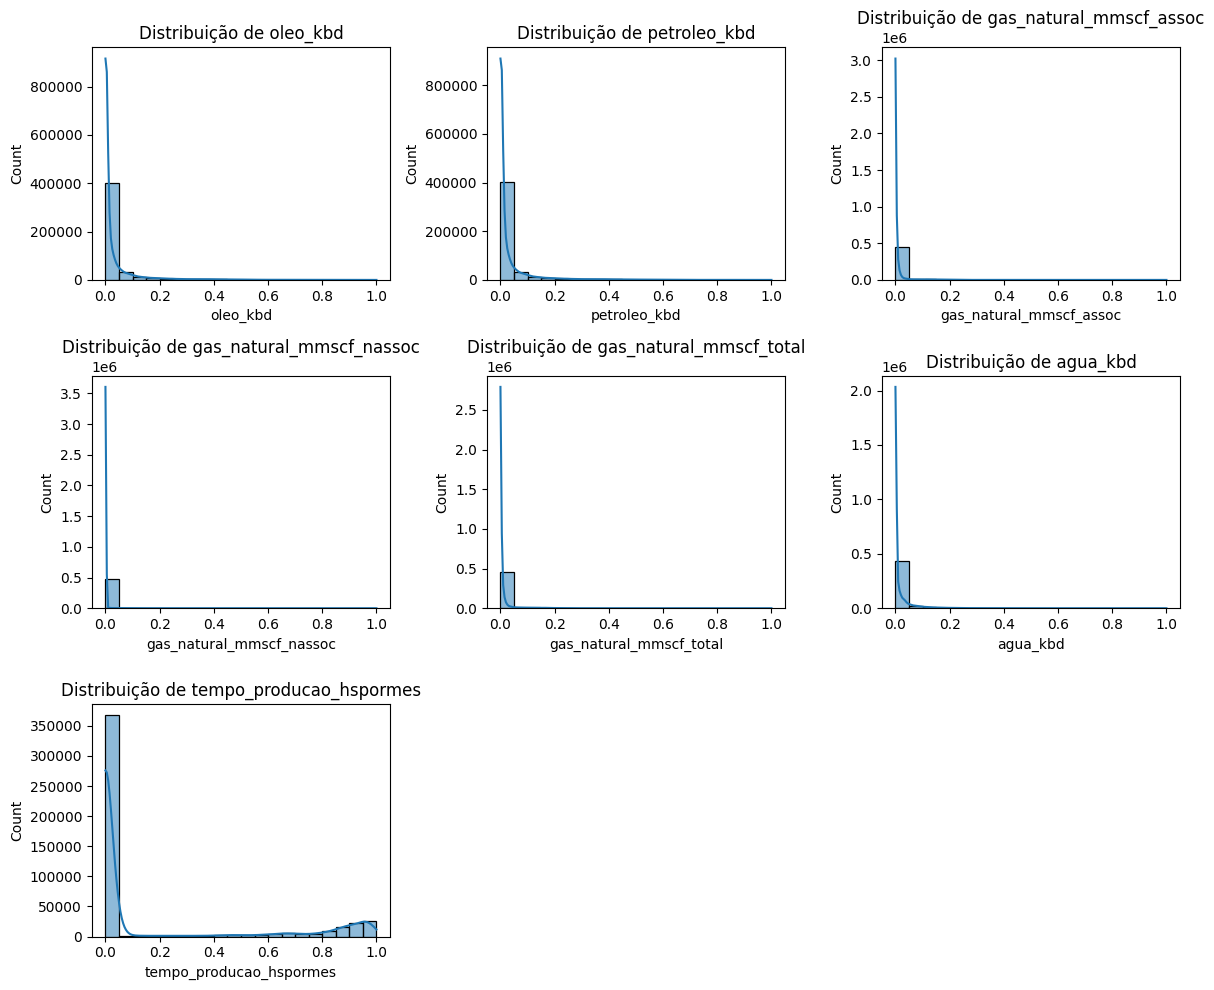

In [118]:
plt.figure(figsize=(12, 10))
for i, coluna in enumerate(colunas_numericas, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df_production_normal[coluna], bins=20, kde=True)
    plt.title(f'Distribuição de {coluna}')
plt.tight_layout()
plt.show()

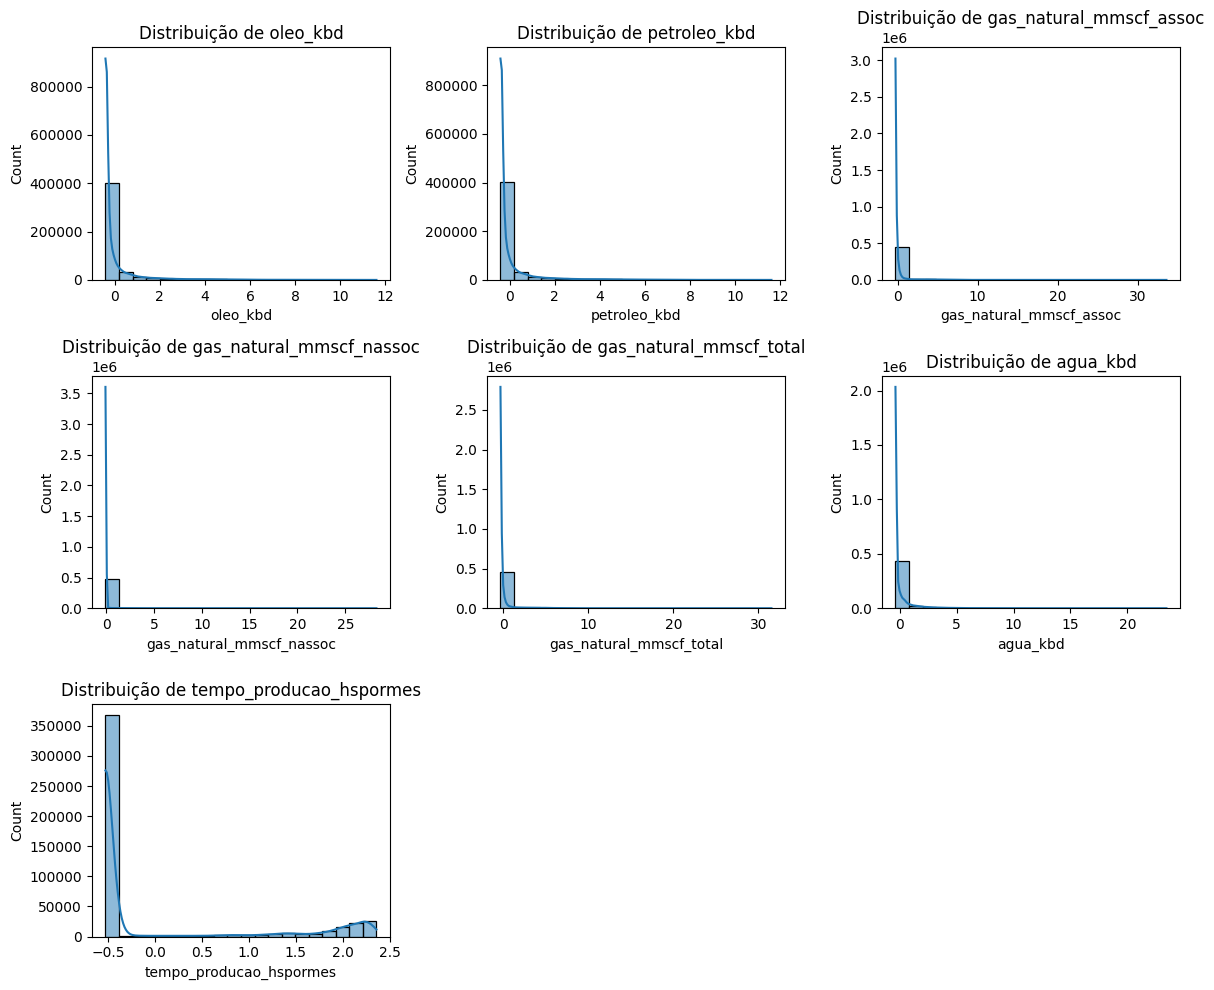

In [119]:
plt.figure(figsize=(12, 10))
for i, coluna in enumerate(colunas_numericas, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df_production_padrao[coluna], bins=20, kde=True)
    plt.title(f'Distribuição de {coluna}')
plt.tight_layout()
plt.show()

## Conclusão

Este projeto consolidou o desenvolvimento de um Mínimo Produto Viável (MVP) para a Sprint "Análise de Dados e Boas Práticas" da PUC-Rio, fundamentado na análise técnica da produção de hidrocarbonetos no Brasil via dados abertos da ANP. Através de um pipeline robusto de extração, saneamento e análise exploratória, foi possível mapear a evolução do setor de Upstream, desde as operações convencionais iniciadas na década de 80 até a atual dominância produtiva da camada do Pré-Sal.

O estudo evidenciou a resiliência da indústria, que manteve um crescimento consistente na produção mesmo diante de desafios globais severos, como a pandemia de COVID-19. As análises iniciais revelaram padrões claros de produtividade, a presença de outliers, que no contexto de petróleo e gás frequentemente representam ativos de altíssima performance, e a necessidade de um gerenciamento eficiente de recursos operacionais. As colunas de dados críticas demonstraram uma qualidade satisfatória após as etapas de pré-processamento e normalização, permitindo uma base sólida para futuras análises que incluam a aplicação de técnicas avançadas de machine learning.

Adicionalmente, as visualizações temporais indicam uma estabilização recente nos volumes produzidos, enfatizando a importância de monitorar as condições de mercado, variações na demanda e influências geopolíticas externas. Este trabalho proporciona uma compreensão abrangente da indústria de petróleo e gás no Brasil e estabelece o alicerce necessário para o desenvolvimento de análises preditivas e de curvas de declínio. Ao integrar práticas de engenharia de software com ciência de dados, o projeto contribui para a geração de insights que permitem decisões mais informadas e estratégicas no setor de energia brasileiro.